# Quality Assessment

In [1]:
import pandas as pd

###Loading DataFrames

In [2]:
# orders_cl.csv
url = "https://drive.google.com/file/d/1QiWLCP_60mpXEYS6A1YEH3S0Whg288xy/view?usp=drive_link"
path = "https://drive.google.com/uc?export=download&id="+url.split("/")[-2]
orders_cl = pd.read_csv(path)

# orderlines_cl.csv
url = "https://drive.google.com/file/d/1hu2Kh3rAOQVC0gGLQN8Zs_HMboVXlu2B/view?usp=drive_link"
path = "https://drive.google.com/uc?export=download&id="+url.split("/")[-2]
orderlines_cl = pd.read_csv(path)

# products_cl.csv
url = "https://drive.google.com/file/d/1IPnKYLSnrST0HBZMeSeNrhFfWU31QvwB/view?usp=drive_link"
path = "https://drive.google.com/uc?export=download&id="+url.split("/")[-2]
products_cl = pd.read_csv(path)

###Further cleaning & corrections

In [3]:
orders_cl.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 226904 entries, 0 to 226903
Data columns (total 4 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   order_id      226904 non-null  int64  
 1   created_date  226904 non-null  object 
 2   total_paid    226904 non-null  float64
 3   state         226904 non-null  object 
dtypes: float64(1), int64(1), object(2)
memory usage: 6.9+ MB


In [4]:
orderlines_cl.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 216250 entries, 0 to 216249
Data columns (total 7 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   id                216250 non-null  int64  
 1   id_order          216250 non-null  int64  
 2   product_id        216250 non-null  int64  
 3   product_quantity  216250 non-null  int64  
 4   sku               216250 non-null  object 
 5   unit_price        216250 non-null  float64
 6   date              216250 non-null  object 
dtypes: float64(1), int64(4), object(2)
memory usage: 11.5+ MB


In [5]:
products_cl.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9992 entries, 0 to 9991
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   sku       9992 non-null   object 
 1   name      9992 non-null   object 
 2   desc      9992 non-null   object 
 3   price     9992 non-null   float64
 4   in_stock  9992 non-null   int64  
 5   type      9946 non-null   object 
dtypes: float64(1), int64(1), object(4)
memory usage: 468.5+ KB


In [6]:
# conversions to datetime

orders_cl['created_date'] = pd.to_datetime(orders_cl['created_date'])
orderlines_cl['date'] = pd.to_datetime(orderlines_cl['date'])

In [7]:
#Removing product_id from orderlines as it is not used

orderlines_cl = orderlines_cl.drop('product_id', axis=1)

## 1.&nbsp; Define Pandas display format

In [8]:
pd.set_option('display.float_format', lambda x: '%.2f' % x)    #Displays floating point numbers to 2 deciimal places only
pd.set_option('display.max_rows', 1000)                        #This displays upto 1000 rows before Pandas starts truncating the output

## 2.&nbsp; Exclude unwanted orders

In [9]:
orderlines_cl['id_order'].nunique()

170213

In [10]:
#To check number of orders in each state

orders_cl['state'].value_counts()

,count
state,
Shopping Basket,117809
Completed,46605
Place Order,40883
Pending,14374
Cancelled,7233


In [11]:
#Discarding orders that were not completed
#Total number of rows with state COMPLETED: 46605  -------> 180299 rows dropped

orders_cl.loc[~(orders_cl['state']== 'Completed'),:].copy()
orders_mod = orders_cl.loc[orders_cl['state']== 'Completed',:].copy()
orders_mod


,order_id,created_date,total_paid,state
1,241423,2017-11-06 13:10:02,136.15,Completed
2,242832,2017-12-31 17:40:03,15.76,Completed
3,243330,2017-02-16 10:59:38,84.98,Completed
5,245275,2017-06-28 11:35:37,149.00,Completed
6,245595,2017-01-21 12:52:47,112.97,Completed
...,...,...,...,...
226544,527042,2018-03-14 11:47:50,18.98,Completed
226572,527070,2018-03-14 11:50:48,24.97,Completed
226576,527074,2018-03-14 11:51:42,24.97,Completed
226598,527096,2018-03-14 11:58:40,34.96,Completed


In [12]:
orders_mod.info()         #Total num rows: 46605

<class 'pandas.core.frame.DataFrame'>
Index: 46605 entries, 1 to 226614
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   order_id      46605 non-null  int64         
 1   created_date  46605 non-null  datetime64[ns]
 2   total_paid    46605 non-null  float64       
 3   state         46605 non-null  object        
dtypes: datetime64[ns](1), float64(1), int64(1), object(1)
memory usage: 1.8+ MB


In [13]:
orderlines_cl.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 216250 entries, 0 to 216249
Data columns (total 6 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   id                216250 non-null  int64         
 1   id_order          216250 non-null  int64         
 2   product_quantity  216250 non-null  int64         
 3   sku               216250 non-null  object        
 4   unit_price        216250 non-null  float64       
 5   date              216250 non-null  datetime64[ns]
dtypes: datetime64[ns](1), float64(1), int64(3), object(1)
memory usage: 9.9+ MB


Discarding orders that are not in orderlines

In [14]:
#List of orders that are NOT present in orderlines
order_list = orderlines_cl['id_order']
orders_mod.loc[~(orders_mod['order_id'].isin(order_list))]


,order_id,created_date,total_paid,state
8,245941,2017-01-01 10:32:23,183.52,Completed
31,257847,2017-11-23 23:46:54,1367.11,Completed
35,258985,2017-07-31 12:52:38,2264.60,Completed
40,259668,2017-10-06 22:06:58,1132.33,Completed
46,262016,2017-08-18 01:05:38,3109.57,Completed
...,...,...,...,...
225860,526357,2018-03-13 12:01:26,1405.99,Completed
225882,526380,2018-03-13 12:16:06,1436.99,Completed
226007,526505,2018-03-13 15:56:14,1421.99,Completed
226009,526507,2018-03-13 16:04:20,1137.97,Completed


In [15]:
#Discarding orders that are not in orderlines (orders –> Keep only orders present in orderlines)
order_list = orderlines_cl['id_order'].unique()
orders_mod = orders_mod.loc[orders_mod['order_id'].isin(order_list),:].copy()      #Total num rows: 79846

In [16]:
orders_mod.info()

<class 'pandas.core.frame.DataFrame'>
Index: 43064 entries, 1 to 226614
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   order_id      43064 non-null  int64         
 1   created_date  43064 non-null  datetime64[ns]
 2   total_paid    43064 non-null  float64       
 3   state         43064 non-null  object        
dtypes: datetime64[ns](1), float64(1), int64(1), object(1)
memory usage: 1.6+ MB


Matching orders in orderlines

In [17]:
#List of orders that are NOT present in orders
new_order_list = orders_mod['order_id'].unique()
orderlines_cl.loc[~(orderlines_cl['id_order'].isin(new_order_list)),:]

,id,id_order,product_quantity,sku,unit_price,date
0,1119109,299539,1,OTT0133,18.99,2017-01-01 00:07:19
1,1119110,299540,1,LGE0043,399.00,2017-01-01 00:19:45
2,1119111,299541,1,PAR0071,474.05,2017-01-01 00:20:57
3,1119112,299542,1,WDT0315,68.39,2017-01-01 00:51:40
4,1119113,299543,1,JBL0104,23.74,2017-01-01 01:06:38
...,...,...,...,...,...,...
216245,1650199,527398,1,JBL0122,42.99,2018-03-14 13:57:25
216246,1650200,527399,1,PAC0653,141.58,2018-03-14 13:57:34
216247,1650201,527400,2,APP0698,9.99,2018-03-14 13:57:41
216248,1650202,527388,1,BEZ0204,19.99,2018-03-14 13:58:01


In [18]:
#orderlines –> Keep only orders present in orders

new_order_list = orders_mod['order_id']
orderlines_mod = orderlines_cl.loc[orderlines_cl['id_order'].isin(new_order_list),:].copy()   #Total num rows remaining: 101375

orderlines_mod.info()

<class 'pandas.core.frame.DataFrame'>
Index: 56714 entries, 6 to 215949
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   id                56714 non-null  int64         
 1   id_order          56714 non-null  int64         
 2   product_quantity  56714 non-null  int64         
 3   sku               56714 non-null  object        
 4   unit_price        56714 non-null  float64       
 5   date              56714 non-null  datetime64[ns]
dtypes: datetime64[ns](1), float64(1), int64(3), object(1)
memory usage: 3.0+ MB


In [19]:
orders_mod.info()

<class 'pandas.core.frame.DataFrame'>
Index: 43064 entries, 1 to 226614
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   order_id      43064 non-null  int64         
 1   created_date  43064 non-null  datetime64[ns]
 2   total_paid    43064 non-null  float64       
 3   state         43064 non-null  object        
dtypes: datetime64[ns](1), float64(1), int64(1), object(1)
memory usage: 1.6+ MB


Finding rows with negative or zero value for total_paid, price & unit_price columns

In [20]:
orders_mod.loc[orders_mod['total_paid'] <= 0]

,order_id,created_date,total_paid,state
150,296010,2017-01-09 23:47:00,0.00,Completed
2061,301495,2017-01-03 12:22:02,0.00,Completed


In [21]:
products_cl.loc[products_cl['price'] <= 0]

,sku,name,desc,price,in_stock,type


In [22]:
orderlines_mod.loc[orderlines_mod['unit_price'] <= 0]

,id,id_order,product_quantity,sku,unit_price,date
51711,1236042,349974,1,LIBRO,0.00,2017-04-26 13:48:27
52044,1236769,350328,1,LIBRO,0.00,2017-04-27 13:05:07
52371,1237477,350677,1,LIBRO,0.00,2017-04-28 11:01:30
52638,1238043,349403,1,LIBRO,0.00,2017-04-28 22:49:20
52783,1238358,351091,1,LIBRO,0.00,2017-04-29 16:28:53
60154,1253019,358293,1,LIBRO,0.00,2017-05-23 09:55:21
60156,1253029,358294,1,LIBRO,0.00,2017-05-23 10:03:36
60775,1254410,358899,1,LIBRO,0.00,2017-05-25 01:53:52
61218,1255378,359326,1,LIBRO,0.00,2017-05-26 10:21:15


Removing rows with such erroneous values

In [23]:
#Listing all order ids that have erroneous values

orders_to_remove = orderlines_mod.loc[orderlines_mod['unit_price'] <= 0]['id_order'].unique()
orders_to_remove

array([349974, 350328, 350677, 349403, 351091, 358293, 358294, 358899,
       359326])

In [24]:
#The above orders are present in 25 rows which need to be removed

orderlines_mod.loc[orderlines_mod['id_order'].isin(orders_to_remove)]

,id,id_order,product_quantity,sku,unit_price,date
51710,1236041,349974,1,APP0911,985.99,2017-04-26 13:48:27
51711,1236042,349974,1,LIBRO,0.00,2017-04-26 13:48:27
51722,1236068,349974,1,PUR0142,12.99,2017-04-26 14:11:13
51728,1236079,349974,1,MUV0168,12.90,2017-04-26 14:23:15
51731,1236084,349974,1,WAC0234,79.99,2017-04-26 14:28:47
51734,1236088,349974,1,LEX0034,53.99,2017-04-26 14:32:02
52043,1236768,350328,1,APP1581,949.00,2017-04-27 13:05:07
52044,1236769,350328,1,LIBRO,0.00,2017-04-27 13:05:07
52370,1237476,350677,1,APP1581,949.00,2017-04-28 11:01:30
52371,1237477,350677,1,LIBRO,0.00,2017-04-28 11:01:30


In [25]:
orderlines_mod.info()

<class 'pandas.core.frame.DataFrame'>
Index: 56714 entries, 6 to 215949
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   id                56714 non-null  int64         
 1   id_order          56714 non-null  int64         
 2   product_quantity  56714 non-null  int64         
 3   sku               56714 non-null  object        
 4   unit_price        56714 non-null  float64       
 5   date              56714 non-null  datetime64[ns]
dtypes: datetime64[ns](1), float64(1), int64(3), object(1)
memory usage: 3.0+ MB


## 3.&nbsp; Exclude orders with unknown products


### 3.1. Analysing SKUs in orderlines & products

In [26]:
products_cl.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9992 entries, 0 to 9991
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   sku       9992 non-null   object 
 1   name      9992 non-null   object 
 2   desc      9992 non-null   object 
 3   price     9992 non-null   float64
 4   in_stock  9992 non-null   int64  
 5   type      9946 non-null   object 
dtypes: float64(1), int64(1), object(4)
memory usage: 468.5+ KB


In [27]:
#List of SKUs from orderlines that are NOT present in products ----> 1394 rows

valid_sku_list = products_cl['sku']
orderlines_mod.loc[(~orderlines_mod['sku'].isin(valid_sku_list)),:]

,id,id_order,product_quantity,sku,unit_price,date
99,1119316,299638,1,SYN0127,223.24,2017-01-01 11:56:18
167,1119477,299706,1,EVU0007,28.49,2017-01-01 13:57:16
173,1119494,299712,1,APP0608,279.99,2017-01-01 14:10:47
303,1119745,299860,1,PAC1516,457.89,2017-01-01 18:40:38
323,1119800,299881,1,SAN0137,49.39,2017-01-01 19:13:45
...,...,...,...,...,...,...
214989,1647363,526037,1,FIB0008,59.99,2018-03-12 16:52:46
214998,1647388,526048,1,SEV0024,59.99,2018-03-12 17:20:40
215056,1647526,526106,1,IFX0020,10.99,2018-03-12 19:09:54
215068,1647561,526122,1,IOT0018,24.99,2018-03-12 20:04:49


In [28]:
products_cl.loc[products_cl['sku']=='PAC1516']

,sku,name,desc,price,in_stock,type


In [29]:
# Valid SKUs that are present in products
valid_sku_list = products_cl['sku']

#Find all id_order that have atleast one unknown SKUs
unknown_sku_order_list = orderlines_mod.loc[~(orderlines_mod['sku'].isin(valid_sku_list)),'id_order'].unique()
unknown_sku_order_list

#Filtering such orders from orderlines
orderlines_mod = orderlines_mod.loc[~(orderlines_mod['id_order'].isin(unknown_sku_order_list))].copy()
orderlines_mod.info()

<class 'pandas.core.frame.DataFrame'>
Index: 54324 entries, 6 to 215949
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   id                54324 non-null  int64         
 1   id_order          54324 non-null  int64         
 2   product_quantity  54324 non-null  int64         
 3   sku               54324 non-null  object        
 4   unit_price        54324 non-null  float64       
 5   date              54324 non-null  datetime64[ns]
dtypes: datetime64[ns](1), float64(1), int64(3), object(1)
memory usage: 2.9+ MB


In [30]:
orders_to_keep = orderlines_mod['id_order'].unique()

orders_mod = orders_mod.loc[orders_mod['order_id'].isin(orders_to_keep),:]

In [31]:
#Checking if there are any rows with total_paid negative or zero

orders_mod.loc[orders_mod['total_paid'] <= 0]

,order_id,created_date,total_paid,state
150,296010,2017-01-09 23:47:00,0.00,Completed
2061,301495,2017-01-03 12:22:02,0.00,Completed


In [32]:
orders_mod.shape, orderlines_mod.shape

((41701, 4), (54324, 6))

In [33]:
orders_mod['order_id'].nunique(), orderlines_mod['id_order'].nunique()

(41701, 41701)

In [34]:
#Removing rows where total_paid <= 0 from orders

orders_with_zero_paid = orders_mod.loc[orders_mod['total_paid'] <= 0,'order_id']

orders_mod = orders_mod.loc[~(orders_mod['order_id'].isin(orders_with_zero_paid)),:]
print(orders_mod.shape)

(41699, 4)


In [35]:
# Keep only orderlines whose 'id_order' exists in cleaned 'orders_mod' table
orderlines_mod = orderlines_mod.loc[orderlines_mod['id_order'].isin(orders_mod['order_id'])]

# Verify that they match now
print("Unique orders in orders_mod:", orders_mod['order_id'].nunique())
print("Unique orders in orderlines_mod:", orderlines_mod['id_order'].nunique())

Unique orders in orders_mod: 41699
Unique orders in orderlines_mod: 41699


In [36]:
orders_mod.shape, orderlines_mod.shape, products_cl.shape

((41699, 4), (54322, 6), (9992, 6))

## 4.&nbsp; Explore the revenue from different tables

Creating a copy of Data frames to work on

In [37]:
orders_s4 = orders_mod.copy()
orderlines_s4 = orderlines_mod.copy()
products_s4 = products_cl.copy()

#### Step 1:
Create the `unit_price_total` as `orderlines.unit_price` * `orderlines.product_quantity`

In [38]:
# create a new column in the orderlines table and store the product of the unit price and quantity

orderlines_s4['unit_price_total'] = orderlines_s4['unit_price'] * orderlines_s4['product_quantity'] # these are total earnings from a given product in a given order

#### Step 2:
Group by `id_order`, summarising by the sum of `unit_price_total`

In [39]:
# aggregate (sum) the total price of all products sold over the column id_order

orderlines_total_price = orderlines_s4.groupby('id_order').agg(total_price=('unit_price_total', 'sum'))
orderlines_total_price

,total_price
id_order,
241423,129.16
242832,10.77
243330,77.99
245275,149.00
245595,105.98
...,...
527042,13.99
527070,19.98
527074,19.98


### What is the average difference between `total_paid` and `unit_price_total`?

In [40]:
# Merge the orders table with the grouped orderlines total
# extract the data of interest - total_paid column from orders table

orders_total_paid = orders_s4[['order_id', 'total_paid']].set_index('order_id')
orders_total_paid

,total_paid
order_id,
241423,136.15
242832,15.76
243330,84.98
245275,149.00
245595,112.97
...,...
527042,18.98
527070,24.97
527074,24.97


In [41]:
# the difference between total_paid (orders) and total_price (orderlines aggregate)

diff_df = orders_total_paid['total_paid'].sub(orderlines_total_price['total_price']).reset_index(name='difference')
diff_df

,order_id,difference
0,241423,6.99
1,242832,4.99
2,243330,6.99
3,245275,0.00
4,245595,6.99
...,...,...
41694,527042,4.99
41695,527070,4.99
41696,527074,4.99
41697,527096,4.99


In [42]:
# check the statistics of the requested difference

diff_df['difference'].describe() # average difference is 4.48

,difference
count,41699.00
mean,4.48
std,26.05
min,-165.00
25%,0.00
50%,4.99
75%,6.99
max,3984.99


### What is the distribution of these differences?

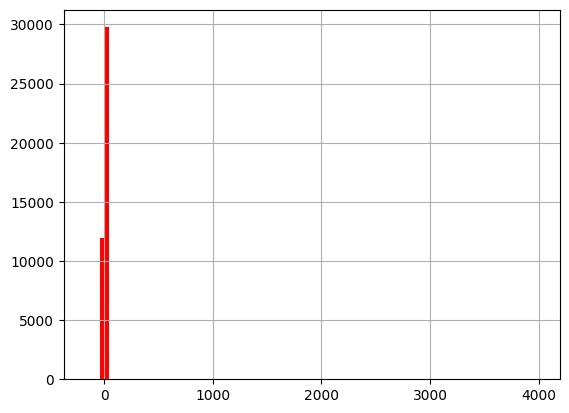

In [43]:
# visualize the distribution of differences with a histogram

diff_df['difference'].hist(bins=100, color='red');

# most diffferences are clustered around the 0 - more than 40000 values are around 0

### Can all the differences be explained by shipping costs? If not, what are other plausible explanations?

In [44]:
# your explanation here
# observe the basic statistics

diff_df['difference'].describe()

# the quartiles correspond to values realistic for shipping cost

# maximum and minimum are confusing - it is unclear what could be the cause for such extreme values

# perhaps there was a mistake in recording the prices

,difference
count,41699.00
mean,4.48
std,26.05
min,-165.00
25%,0.00
50%,4.99
75%,6.99
max,3984.99


### If there are differences that you can’t explain: what should you do with these orders?

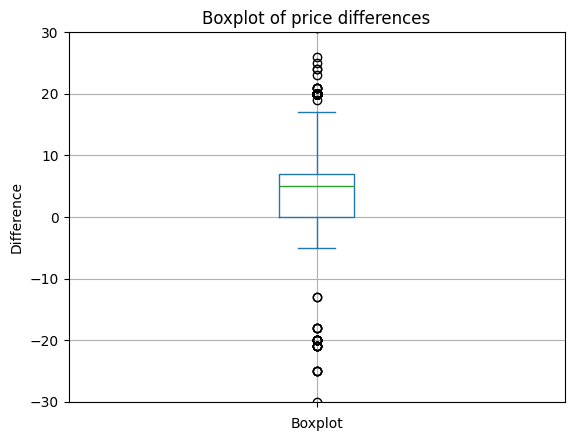

In [45]:
# let's first visualize the boxplot of differences

import matplotlib.pyplot as plt

ax = diff_df['difference'].plot.box()
ax.set_ylim(-30, 30)
ax.grid()

ax.set_xticklabels([]) # removes the automatic labeling of the x axis

plt.title('Boxplot of price differences') # set title
plt.xlabel('Boxplot')                     # set x label
plt.ylabel('Difference')                  # set y label

plt.show()

# we can get rid of the outliers and remove the orders that correspond to them

### Removal of the outliers and corresponding orders

In [46]:
# to detect the outliers, we first have to find the upper and lower whisker values, and then the interquartile range (IQR)

# we can read the main quartiles from the .describe() method's output

q1 = 0
q2 = 4.99
q3 = 6.99

# or we can call appropriate methods

q1 = diff_df['difference'].quantile(0.25)
q2 = diff_df['difference'].quantile(0.5)
q3 = diff_df['difference'].quantile(0.75)

# calculate the relevant boundaries

iqr = q3 - q1                  # calculate the interquartile range (IQR)
lower_whisker = q1 - 1.5 * iqr # find the value of the lower whisker
upper_whisker = q3 + 1.5 * iqr # find the value of the upper whisker

# we will remove orders related to differences that fall outside of the whiskers

In [47]:
# create a mask for differences outside of the whiskers

extreme_differences_mask = (diff_df['difference'] < lower_whisker) | (diff_df['difference'] > upper_whisker)
num_outliers = extreme_differences_mask.sum()
num_outliers

# we discover that there are 714 outliers, which is acceptable, given that we are considering more than 40000 orders

np.int64(714)

In [48]:
# apply the mask

sensible_orders = diff_df.loc[~extreme_differences_mask, 'order_id'] # extract the orders to be kept

orders_s4 = orders_s4.loc[orders_s4['order_id'].isin(sensible_orders), :]             # perform the filtering of orders table
orderlines_s4 = orderlines_s4.loc[orderlines_s4['id_order'].isin(sensible_orders), :] # perform the filtering of orderlines table

# we kept only those orders for which the difference between total_paid and unit_price_total_paid is realistically small

orders_s4['order_id'].nunique(), orderlines_s4['id_order'].nunique()

(40985, 40985)

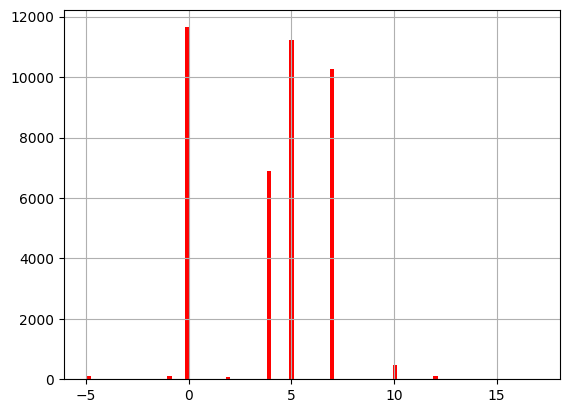

In [49]:
# visualize the differences in total paid price when the outliers are gone

diff_df.loc[~extreme_differences_mask, 'difference'].hist(bins=100, color='red');

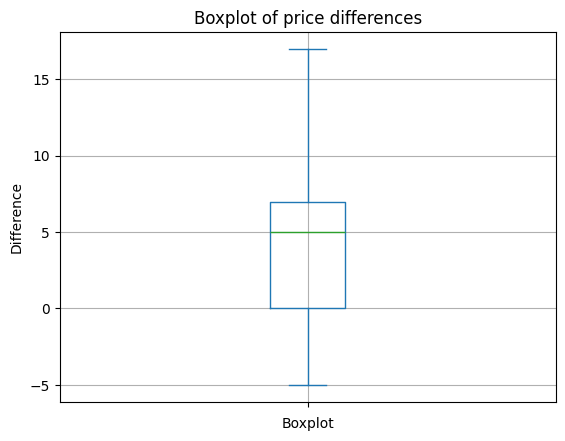

In [50]:
# visualize the differences boxplot after the outliers have been removed

ax = diff_df.loc[~extreme_differences_mask, 'difference'].plot.box()

ax.grid()
ax.set_xticklabels([]) # removes the automatic labeling of the x axis

plt.title('Boxplot of price differences') # title
plt.xlabel('Boxplot')                     # x label
plt.ylabel('Difference')                  # y label

plt.show()

In [51]:
orders_s4.info()

<class 'pandas.core.frame.DataFrame'>
Index: 40985 entries, 1 to 226614
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   order_id      40985 non-null  int64         
 1   created_date  40985 non-null  datetime64[ns]
 2   total_paid    40985 non-null  float64       
 3   state         40985 non-null  object        
dtypes: datetime64[ns](1), float64(1), int64(1), object(1)
memory usage: 1.6+ MB


In [52]:
orderlines_s4.info()

<class 'pandas.core.frame.DataFrame'>
Index: 53231 entries, 6 to 215949
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   id                53231 non-null  int64         
 1   id_order          53231 non-null  int64         
 2   product_quantity  53231 non-null  int64         
 3   sku               53231 non-null  object        
 4   unit_price        53231 non-null  float64       
 5   date              53231 non-null  datetime64[ns]
 6   unit_price_total  53231 non-null  float64       
dtypes: datetime64[ns](1), float64(2), int64(3), object(1)
memory usage: 3.2+ MB


In [53]:
products_s4.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9992 entries, 0 to 9991
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   sku       9992 non-null   object 
 1   name      9992 non-null   object 
 2   desc      9992 non-null   object 
 3   price     9992 non-null   float64
 4   in_stock  9992 non-null   int64  
 5   type      9946 non-null   object 
dtypes: float64(1), int64(1), object(4)
memory usage: 468.5+ KB


####Downloading cleaned CSV files on local system

In [54]:
#Importing the latest version of tables as CSV

from google.colab import files

orders_s4.to_csv("orders_s4.csv", index=False) # store the cleaned up data so it's available for later use
files.download("orders_s4.csv")

orderlines_s4.to_csv("orderlines_s4.csv", index=False)
files.download("orderlines_s4.csv")

products_s4.to_csv("products_s4.csv", index=False)
files.download("products_s4.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

##Revenue Generation Analysis

In [55]:
#Total Revenue Generated
total_revenue = orderlines_s4['unit_price_total'].sum()
rounded_revenue = round(total_revenue, 2)

print("Total Revenue: €", rounded_revenue)

Total Revenue: € 7817204.4


##Business Questions

##Part 1: Set of code by one group member
This being a group project the code from 2 notebooks is present in this merged notebook. This is the 1st part.

####How many products are being discounted?

In [56]:
# Merged orderlines_s4 with products_s4 on 'sku' to compare selling price vs catalog price
merged_products = orderlines_s4.merge(products_s4, on='sku', suffixes=('_order', '_catalog'))

# A product is discounted if its unit_price is less than its catalog price
discounted_mask = merged_products['unit_price'] < merged_products['price']

# Count unique products (SKUs) that have been sold at a discount at least once
num_discounted_products = merged_products.loc[discounted_mask, 'sku'].nunique()

print(f"Number of unique products being discounted: {num_discounted_products}")     #4906

# Optional: View a breakdown of the discounted products and how often they were discounted
discounted_summary = merged_products.loc[discounted_mask, ['sku', 'name', 'unit_price', 'price']].drop_duplicates()
display(discounted_summary.head(10))

Number of unique products being discounted: 4906


,sku,name,unit_price,price
0,OWC0100,OWC In-line Digital Temperature Sensor Kit HDD...,47.49,60.99
1,IOT0014,iOttie Easy View 2 Car Black Support,18.99,22.95
2,APP0700,Apple 85W MagSafe 2 charger MacBook Pro screen...,72.19,89.00
3,CRU0039-A,(Open) Crucial 240GB SSD 7mm BX200,60.90,76.99
4,PEB0015,Pebble Smartwatch Time Steel Black,142.49,299.99
5,BEA0065,Solo3 Beats Headphones Wireless On-Ear Rose Gold,256.49,299.95
6,SAT0010,Satechi Aluminum Silver Mouse,18.99,29.99
7,SYN0139,Synology DS216j NAS Server Mac and PC,166.24,175.99
8,LOG0191,Ultimate Ears Boom 2 Bluetooth Portable Speake...,142.49,209.00
9,LGE0031-A,"Open - LG Monitor 24 ""W 5ms HDMI 24MP58VQ-White",127.08,159.00


####How big are the offered discounts as a percentage of the product prices?

On Average Discounted products are sold 23.24 times more

In [57]:
# Filter for rows where a discount occurred (selling price < catalog price)
discounted_df = merged_products[merged_products['unit_price'] < merged_products['price']].copy()

# Calculate the discount percentage for each discounted order line
discounted_df['discount_percentage'] = ((discounted_df['price'] - discounted_df['unit_price']) / discounted_df['price']) * 100

# View summary statistics of the discount percentages (mean, min, max, quartiles)
print("Discount Percentage Summary Statistics:")
print(discounted_df['discount_percentage'].describe())

# Optional: View a preview table showing the SKU, name, standard price, selling price, and discount %
summary_columns = ['sku', 'name', 'price', 'unit_price', 'discount_percentage']
display(discounted_df[summary_columns].head(10))

Discount Percentage Summary Statistics:
count   49404.00
mean       23.24
std        17.33
min         0.00
25%        11.11
50%        19.54
75%        29.97
max        97.14
Name: discount_percentage, dtype: float64


,sku,name,price,unit_price,discount_percentage
0,OWC0100,OWC In-line Digital Temperature Sensor Kit HDD...,60.99,47.49,22.13
1,IOT0014,iOttie Easy View 2 Car Black Support,22.95,18.99,17.25
2,APP0700,Apple 85W MagSafe 2 charger MacBook Pro screen...,89.00,72.19,18.89
3,CRU0039-A,(Open) Crucial 240GB SSD 7mm BX200,76.99,60.90,20.90
4,PEB0015,Pebble Smartwatch Time Steel Black,299.99,142.49,52.50
5,BEA0065,Solo3 Beats Headphones Wireless On-Ear Rose Gold,299.95,256.49,14.49
6,SAT0010,Satechi Aluminum Silver Mouse,29.99,18.99,36.68
7,SYN0139,Synology DS216j NAS Server Mac and PC,175.99,166.24,5.54
8,LOG0191,Ultimate Ears Boom 2 Bluetooth Portable Speake...,209.00,142.49,31.82
9,LGE0031-A,"Open - LG Monitor 24 ""W 5ms HDMI 24MP58VQ-White",159.00,127.08,20.08


## Discount Buckets & Revenue analysis

####Merging Datasets

In [58]:
#Merging the Datasets
#Merging orders & orderlines

orderlines_order = orderlines_s4.merge(orders_s4, left_on='id_order', right_on='order_id')
orderlines_order.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53231 entries, 0 to 53230
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   id                53231 non-null  int64         
 1   id_order          53231 non-null  int64         
 2   product_quantity  53231 non-null  int64         
 3   sku               53231 non-null  object        
 4   unit_price        53231 non-null  float64       
 5   date              53231 non-null  datetime64[ns]
 6   unit_price_total  53231 non-null  float64       
 7   order_id          53231 non-null  int64         
 8   created_date      53231 non-null  datetime64[ns]
 9   total_paid        53231 non-null  float64       
 10  state             53231 non-null  object        
dtypes: datetime64[ns](2), float64(3), int64(4), object(2)
memory usage: 4.5+ MB


In [59]:
#Merging the merged table with products
merged_datasets = orderlines_order.merge(products_s4,on='sku',how='left')
merged_datasets.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53231 entries, 0 to 53230
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   id                53231 non-null  int64         
 1   id_order          53231 non-null  int64         
 2   product_quantity  53231 non-null  int64         
 3   sku               53231 non-null  object        
 4   unit_price        53231 non-null  float64       
 5   date              53231 non-null  datetime64[ns]
 6   unit_price_total  53231 non-null  float64       
 7   order_id          53231 non-null  int64         
 8   created_date      53231 non-null  datetime64[ns]
 9   total_paid        53231 non-null  float64       
 10  state             53231 non-null  object        
 11  name              53231 non-null  object        
 12  desc              53231 non-null  object        
 13  price             53231 non-null  float64       
 14  in_stock          5323

####Discount percentage calculation

In [60]:
# Calculate the discount percentage for each row
merged_datasets['discount_pct'] = (
    (merged_datasets['price'] - merged_datasets['unit_price']) / merged_datasets['price']) * 100


merged_datasets[['sku', 'name', 'price', 'unit_price', 'discount_pct']].head(10)

,sku,name,price,unit_price,discount_pct
0,OWC0100,OWC In-line Digital Temperature Sensor Kit HDD...,60.99,47.49,22.13
1,IOT0014,iOttie Easy View 2 Car Black Support,22.95,18.99,17.25
2,APP0700,Apple 85W MagSafe 2 charger MacBook Pro screen...,89.00,72.19,18.89
3,CRU0039-A,(Open) Crucial 240GB SSD 7mm BX200,76.99,60.90,20.90
4,PEB0015,Pebble Smartwatch Time Steel Black,299.99,142.49,52.50
5,BEA0065,Solo3 Beats Headphones Wireless On-Ear Rose Gold,299.95,256.49,14.49
6,SAT0010,Satechi Aluminum Silver Mouse,29.99,18.99,36.68
7,SYN0139,Synology DS216j NAS Server Mac and PC,175.99,166.24,5.54
8,LOG0191,Ultimate Ears Boom 2 Bluetooth Portable Speake...,209.00,142.49,31.82
9,LGE0031-A,"Open - LG Monitor 24 ""W 5ms HDMI 24MP58VQ-White",159.00,127.08,20.08


In [61]:
merged_datasets['discount_pct'].isnull().sum()

np.int64(0)

In [62]:
merged_datasets.shape

(53231, 17)

In [63]:
#Assigning markups - where unit_price is higher than catalog price
markups = merged_datasets.loc[merged_datasets['discount_pct'] <= 0,:]
len(markups)                                                         #Num rows with pct <= 0: 3827

3827

In [64]:
#Percentage of markups(Unit price higher or equal to catalog price)

(len(markups)/len(merged_datasets)) * 100

7.189419699047547

####Discount buckets creation

In [65]:
#Creating discount buckets

import numpy as np

#Using np.select for this. It's like CASE WHEN in SQL.
#Each row is checked against the condition & assigned respective value.
#When no match is found, default value is assigned.

# Define conditions for markups, full price, and each discount tier
conditions = [
    merged_datasets['discount_pct'] < 0,                                       # Markup (unit price > list price)
    merged_datasets['discount_pct'] == 0,                                                # Full Price (0%)
    (merged_datasets['discount_pct'] > 0) & (merged_datasets['discount_pct'] <= 10),     # 1–10% discount
    (merged_datasets['discount_pct'] > 10) & (merged_datasets['discount_pct'] <= 25),    # 10–25% discount
    (merged_datasets['discount_pct'] > 25) & (merged_datasets['discount_pct'] <= 50),    # 25–50% discount
    merged_datasets['discount_pct'] > 50                                                 # 50%+ discount
]

choices = [
    'Markup (< 0%)',
    'Full Price (0%)',
    '1–10%',
    '10–25%',
    '25–50%',
    '50%+'
]

# Apply the conditions to create the bucket column
merged_datasets['discount_bucket'] = np.select(conditions, choices, default='Unknown')

# Preview the bucket counts to verify the distribution
print(merged_datasets['discount_bucket'].value_counts())

discount_bucket
10–25%             21765
25–50%             12158
1–10%              10506
50%+                4975
Full Price (0%)     2256
Markup (< 0%)       1571
Name: count, dtype: int64


####Revenue summary per discount bucket

In [66]:
# Aggregate Revenue and Units Sold by Discount Bucket

#observed=False: Pandas will show all pre-defined categories in list, even if a specific bucket has 0 transactions.
revenue_summary = merged_datasets.groupby('discount_bucket', observed=False).agg(
    total_revenue=('unit_price_total', 'sum'),       # Total revenue generated per bucket
    total_units_sold=('product_quantity', 'sum'),    # Total quantity of items sold per bucket
    total_transactions=('id_order', 'count')         # Number of transaction lines per bucket
).reset_index()


# Calculate the percentage share of overall revenue for each bucket
total_overall_revenue = revenue_summary['total_revenue'].sum()
revenue_summary['revenue_share_pct'] = (revenue_summary['total_revenue'] / total_overall_revenue) * 100

# Round numerical columns for clean presentation
revenue_summary['total_revenue'] = revenue_summary['total_revenue'].round(2)
revenue_summary['revenue_share_pct'] = revenue_summary['revenue_share_pct'].round(2)

# Display the final summary table
display(revenue_summary)

,discount_bucket,total_revenue,total_units_sold,total_transactions,revenue_share_pct
0,10–25%,3471643.32,24707,21765,44.41
1,1–10%,2647204.05,11693,10506,33.86
2,25–50%,973516.85,13486,12158,12.45
3,50%+,149759.20,5784,4975,1.92
4,Full Price (0%),241598.04,2561,2256,3.09
5,Markup (< 0%),333482.94,1780,1571,4.27


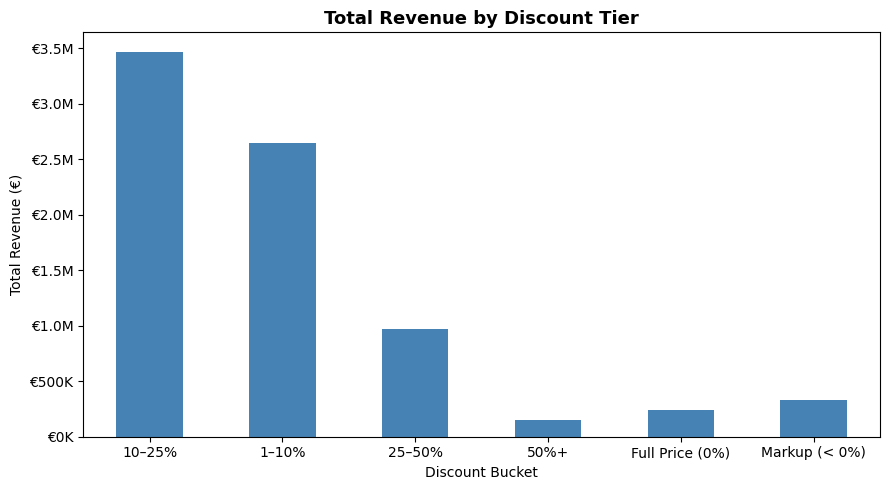

In [67]:
#Plot for Revenue pere Discount bucket

import matplotlib.pyplot as plt

# Create the bar plot using the table from Step 1
ax = revenue_summary.plot(kind='bar', x='discount_bucket', y='total_revenue', legend=False, figsize=(9, 5), color='steelblue')

# Titles and axis labels
plt.title('Total Revenue by Discount Tier', fontsize=13, fontweight='bold')
plt.xlabel('Discount Bucket')
plt.ylabel('Total Revenue (€)')

# Format y-axis dynamically (M for millions, K for thousands)
ax.yaxis.set_major_formatter(lambda x, pos: f'€{x*1e-6:,.1f}M' if x >= 1e6 else f'€{x*1e-3:,.0f}K')

# Keep x-axis labels horizontal
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

/tmp/ipykernel_1286/2879688651.py:54: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([f'€{val*1e-6:.1f}M' for val in current_ticks], fontsize=10)


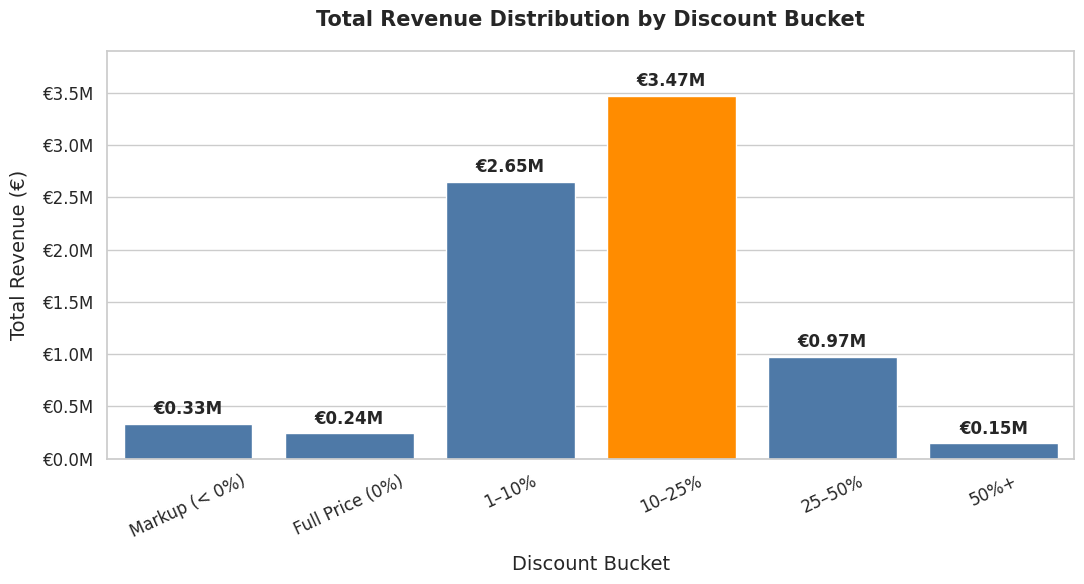

In [68]:
#FINAL PLOT to display Total Revenue Distribution by Discount Bucket

import matplotlib.pyplot as plt
import seaborn as sns

# Define the logical order of discount buckets from lowest to highest discount depth
bucket_order = [
    'Markup (< 0%)',
    'Full Price (0%)',
    '1–10%',
    '10–25%',
    '25–50%',
    '50%+',
]

# Set up the plot size and style
plt.figure(figsize=(11, 6))
sns.set_theme(style='whitegrid')

# Define custom colors
COLOR_STEEL_BLUE = '#4E79A7'  # Remaining bars
COLOR_TANGERINE = '#FF8C00'  # Highest bar

# Create the bar chart (using a placeholder color first)
ax = sns.barplot(
    data=revenue_summary,
    x='discount_bucket',
    y='total_revenue',
    order=bucket_order,
    color=COLOR_STEEL_BLUE,
)

# Dynamically find the tallest bar and color it Tangerine, others Steel Blue
max_height = max(p.get_height() for p in ax.patches)
for p in ax.patches:
  if p.get_height() == max_height:
    p.set_facecolor(COLOR_TANGERINE)
  else:
    p.set_facecolor(COLOR_STEEL_BLUE)

# Add title and labels optimized for a presentation
plt.title(
    'Total Revenue Distribution by Discount Bucket',
    fontsize=15,
    fontweight='bold',
    pad=18,
)
plt.xlabel('Discount Bucket', fontsize=14, labelpad=10)
plt.ylabel('Total Revenue (€)', fontsize=14, labelpad=10)
plt.xticks(rotation=25, fontsize=12)

# Format y-axis in Millions (€M) for cleaner executive readability
current_ticks = plt.yticks()[0]
ax.set_yticklabels([f'€{val*1e-6:.1f}M' for val in current_ticks], fontsize=10)
# Clean Y-axis formatting without the warning
ax.set_yticks([0e6, 0.5e6, 1.0e6, 1.5e6, 2.0e6, 2.5e6, 3.0e6, 3.5e6])
ax.set_yticklabels(
    ['€0.0M', '€0.5M', '€1.0M', '€1.5M', '€2.0M', '€2.5M', '€3.0M', '€3.5M'],
    fontsize=12,
)
ax.set_ylim(0, 3.9e6)

# Add data labels on top of each bar (showing Euros in millions)
for p in ax.patches:
  height = p.get_height()
  if height > 0:  # Avoid labeling empty bars if any
    ax.annotate(
        f'€{height*1e-6:.2f}M',
        (p.get_x() + p.get_width() / 2.0, height),
        ha='center',
        va='bottom',
        xytext=(0, 4),
        textcoords='offset points',
        fontsize=12,
        fontweight='semibold',
    )

plt.tight_layout()

#Saving the file in .svg format
plt.savefig(
    'total_revenue_distribution_by_discount_bucket.svg',
    format='svg',
    bbox_inches='tight',  # Ensures labels, titles, and ticks are never cut off
    transparent=True,
)

plt.show()

#####Downloading the plot in .svg format

In [69]:
#Importing & downloading the .svg file

import os
print([f for f in os.listdir() if f.endswith('.svg')])

from google.colab import files
files.download('total_revenue_distribution_by_discount_bucket.svg')

['total_revenue_distribution_by_discount_bucket.svg']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 6.&nbsp; 🧩 Keep asking questions(LMS)

In [70]:
# 1. What is the time period that the dataset covers?

min_date = orders_s4['created_date'].min()
max_date = orders_s4['created_date'].max()
print(f"Time Period: From {min_date.strftime('%Y-%m-%d')} to {max_date.strftime('%Y-%m-%d')}")

Time Period: From 2017-01-01 to 2018-03-14


In [71]:
# 2. What is the overall revenue for that time?

overall_revenue = merged_datasets['unit_price_total'].sum().round(2)
print(f"Overall Revenue: €{overall_revenue}")

Overall Revenue: €7817204.4


In [72]:
#Are there seasonal patterns in the evolution of sales? (Monthly aggregated sales)

monthly_sales = (merged_datasets.set_index('created_date')
.resample('ME')['unit_price_total'].sum().round(2)).reset_index()

monthly_sales

,created_date,unit_price_total
0,2017-01-31,604091.87
1,2017-02-28,332612.30
2,2017-03-31,24856.02
3,2017-04-30,228090.63
4,2017-05-31,331214.98
5,2017-06-30,286575.67
6,2017-07-31,599404.93
7,2017-08-31,379560.32
8,2017-09-30,387942.85
9,2017-10-31,547599.55


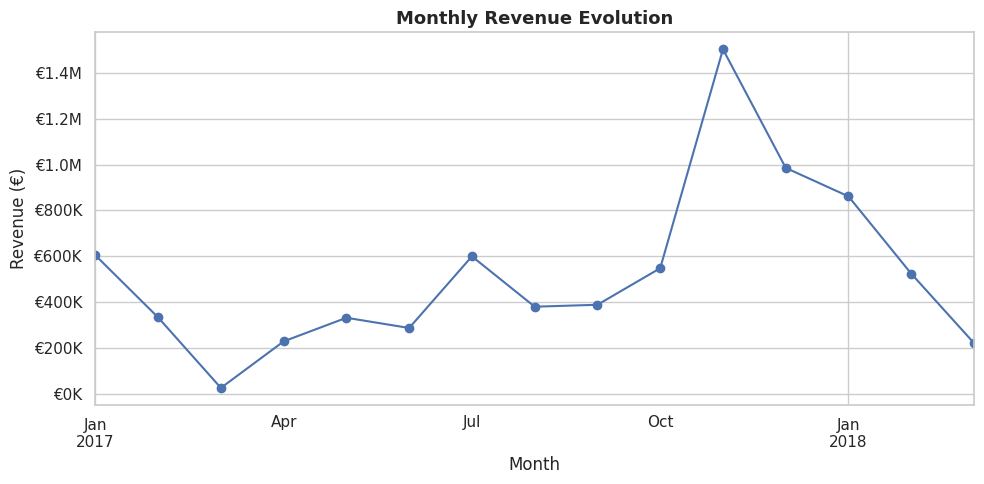

In [73]:
import matplotlib.pyplot as plt

# 1. Plot the monthly sales directly
ax = monthly_sales.plot(x='created_date', y='unit_price_total', kind='line', marker='o', legend=False, figsize=(10, 5))

# 2. Add titles and labels
plt.title('Monthly Revenue Evolution', fontsize=13, fontweight='bold')
plt.xlabel('Month')
plt.ylabel('Revenue (€)')

# 3. Format y-axis in K/M
ax.yaxis.set_major_formatter(lambda x, pos: f'€{x*1e-6:,.1f}M' if x >= 1e6 else f'€{x*1e-3:,.0f}K')

plt.tight_layout()
plt.show()

In [74]:
merged_datasets.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53231 entries, 0 to 53230
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   id                53231 non-null  int64         
 1   id_order          53231 non-null  int64         
 2   product_quantity  53231 non-null  int64         
 3   sku               53231 non-null  object        
 4   unit_price        53231 non-null  float64       
 5   date              53231 non-null  datetime64[ns]
 6   unit_price_total  53231 non-null  float64       
 7   order_id          53231 non-null  int64         
 8   created_date      53231 non-null  datetime64[ns]
 9   total_paid        53231 non-null  float64       
 10  state             53231 non-null  object        
 11  name              53231 non-null  object        
 12  desc              53231 non-null  object        
 13  price             53231 non-null  float64       
 14  in_stock          5323

In [75]:
# 4. What are the most sold products (by quantity)?

top_products_qty = (
    merged_datasets.groupby(['sku', 'name'])['product_quantity']
    .sum()
    .reset_index()
    .sort_values(by='product_quantity', ascending=False)
    .head(5)
)

top_products_qty

,sku,name,product_quantity
448,APP1190,IPhone AppleCare Protection Plan,955
360,APP0698,Apple Lightning Cable Connector to USB 1m Whit...,820
655,APP1922,AirPods Apple Bluetooth Headset for iPhone iPa...,537
378,APP0927,EarPods Apple Headphones with Remote and Mic (...,489
4906,WDT0183,"Red 4TB WD 35 ""Mac PC hard drive and NAS",476


In [76]:
# 5. What are the products that generate the most revenue?

top_products_rev = (
    merged_datasets.groupby(['sku', 'name'])['unit_price_total']
    .sum()
    .sort_values(ascending=False)
    .head(5)
)

top_products_rev

,,unit_price_total
sku,name,
LGE0044,"LG 27UD88-W Monitor 27 ""UHD 4K USB 3.0 USB-C",135375.83
APP2446,Apple iPhone 6 32GB Space Gray,104560.64
APP1922,AirPods Apple Bluetooth Headset for iPhone iPad iPod and Apple Watch,86473.26
APP2477,Apple iPhone 64GB Space Gray 8,85301.93
APP1970,Apple iPhone 32GB Space Gray,80715.76


## 7.&nbsp; 🧩 Analyze discounts(LMS)
Used Discount pct instead of creating a new column for Discount


In [77]:
#Grouping my Month to introduce time dimension


monthly_avg_discount = (
    merged_datasets.set_index('created_date')
    .resample('ME')['discount_pct']
    .mean()
    .rename('discount_pct_avg')
.reset_index()
)

display(monthly_avg_discount)

,created_date,discount_pct_avg
0,2017-01-31,24.87
1,2017-02-28,19.54
2,2017-03-31,19.05
3,2017-04-30,18.26
4,2017-05-31,15.40
5,2017-06-30,17.16
6,2017-07-31,24.98
7,2017-08-31,20.49
8,2017-09-30,20.02
9,2017-10-31,22.05


In [78]:
#Merging the data to get revenue included
monthly_df = monthly_avg_discount.merge(monthly_sales, on='created_date',how = 'inner')

#Renaming unit_price_total to monthly_revenue
monthly_df = monthly_df.rename(
    columns={'unit_price_total': 'monthly_revenue'}
)

monthly_df

,created_date,discount_pct_avg,monthly_revenue
0,2017-01-31,24.87,604091.87
1,2017-02-28,19.54,332612.30
2,2017-03-31,19.05,24856.02
3,2017-04-30,18.26,228090.63
4,2017-05-31,15.40,331214.98
5,2017-06-30,17.16,286575.67
6,2017-07-31,24.98,599404.93
7,2017-08-31,20.49,379560.32
8,2017-09-30,20.02,387942.85
9,2017-10-31,22.05,547599.55


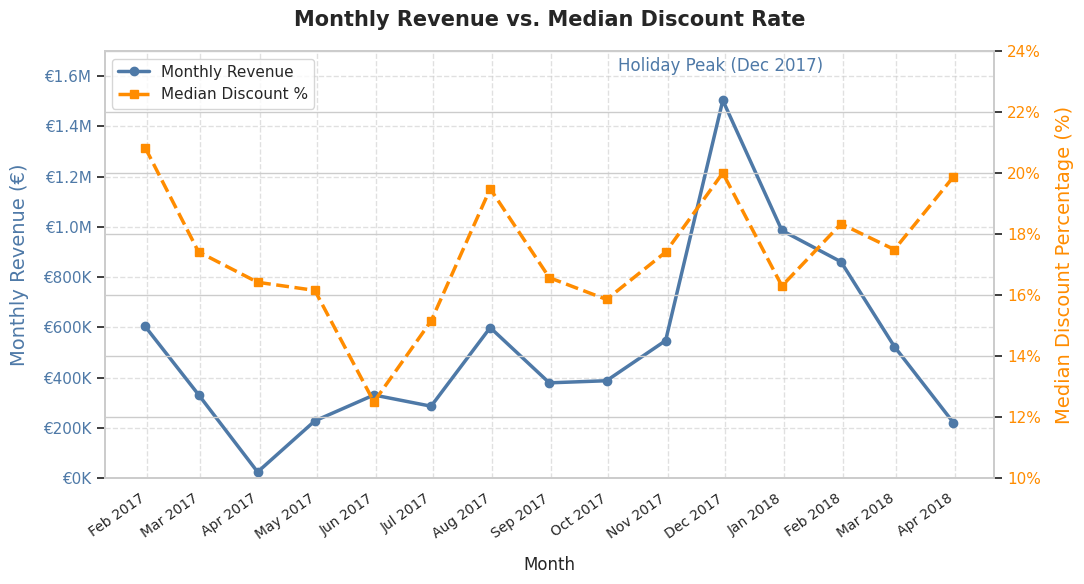

In [79]:
#Plot in Backup slides in final presentation deck
#FINAL PLOT for Monthly Revenue & Discount Percentage (Median)

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import pandas as pd
import seaborn as sns

# 1. Monthly Aggregation
discount_col = 'discount_pct'  # Update if your discount column has a different name
monthly_df = (
    merged_datasets.groupby(pd.Grouper(key='created_date', freq='ME'))
    .agg(
        monthly_revenue=('unit_price_total', 'sum'),
        median_discount=(discount_col, 'median'),
    )
    .reset_index()
)

# 2. Figure Setup & Styling
fig, ax1 = plt.subplots(figsize=(11, 6))
sns.set_theme(style='whitegrid')

COLOR_STEEL_BLUE = '#4E79A7'  # Muted Steel Blue (Revenue)
COLOR_TANGERINE = '#FF8C00'  # Bright Tangerine (Median Discount)

# 3. Primary Axis: Monthly Revenue (Left)
ax1.set_xlabel('Month', fontsize=12, labelpad=10)
ax1.set_ylabel(
    'Monthly Revenue (€)', color=COLOR_STEEL_BLUE, fontsize=14, labelpad=10
)
line1 = ax1.plot(
    monthly_df['created_date'],
    monthly_df['monthly_revenue'],
    color=COLOR_STEEL_BLUE,
    marker='o',
    linewidth=2.5,
    label='Monthly Revenue',
)
ax1.tick_params(axis='y', labelcolor=COLOR_STEEL_BLUE)
ax1.yaxis.set_major_formatter(
    FuncFormatter(
        lambda x, _: f'€{x*1e-6:.1f}M' if x >= 1e6 else f'€{x*1e-3:.0f}K'
    )
)
ax1.set_ylim(0, 1.7e6)

# 4. Secondary Axis: Median Discount (Right)
ax2 = ax1.twinx()
ax2.set_ylabel(
    'Median Discount Percentage (%)',
    color=COLOR_TANGERINE,
    fontsize=14,
    labelpad=10,
)
line2 = ax2.plot(
    monthly_df['created_date'],
    monthly_df['median_discount'],
    color=COLOR_TANGERINE,
    marker='s',
    linewidth=2.5,
    linestyle='--',
    label='Median Discount %',
)
ax2.tick_params(axis='y', labelcolor=COLOR_TANGERINE)
ax2.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x:.0f}%'))
ax2.set_ylim(10, 24)

# 5. X-Axis Formatting & Rotation
ax1.xaxis.set_major_locator(mdates.MonthLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.setp(ax1.get_xticklabels(), rotation=35, ha='right', fontsize=10)

# 6. Legend, Title & Grid
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper left', frameon=True, fontsize=11)

plt.title(
    'Monthly Revenue vs. Median Discount Rate',
    fontsize=15,
    fontweight='bold',
    pad=18,
)
ax1.grid(True, linestyle='--', alpha=0.6)

# 7. Executive Text Label (Arrow Removed)
ax1.text(
    monthly_df.loc[monthly_df['monthly_revenue'].idxmax(), 'created_date']
    - pd.Timedelta(days=55),
    1.62e6,
    'Holiday Peak (Dec 2017)',
    fontsize=12,
    #fontweight='bold',
    color=COLOR_STEEL_BLUE,
)



# 8. Render Plot
plt.tight_layout()

# 2. Exporting the figure
plt.savefig(
    'monthly_revenue_vs_median_discount.svg',
    format='svg',
    bbox_inches='tight',
    transparent=True,
)

plt.show()

#####Downloading the plot in .svg format

In [80]:
#Importing & downloading the .svg file

import os
print([f for f in os.listdir() if f.endswith('.svg')])

from google.colab import files
files.download('monthly_revenue_vs_median_discount.svg')

['total_revenue_distribution_by_discount_bucket.svg', 'monthly_revenue_vs_median_discount.svg']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

##Correlation between Monthly Revenue & Median Discount %

In [81]:
# Calculate Pearson correlation between monthly revenue and median discount
correlation_matrix = monthly_df[['monthly_revenue', 'median_discount']].corr()
print('Correlation Matrix:')
print(correlation_matrix)

# If you want a specific statistical p-value check using scipy:
from scipy.stats import pearsonr

corr_coef, p_value = pearsonr(
    monthly_df['monthly_revenue'], monthly_df['median_discount']
)
print(f'\nPearson Correlation Coefficient: {corr_coef:.2f}')
print(f'P-value: {p_value:.4f}')

Correlation Matrix:
                 monthly_revenue  median_discount
monthly_revenue             1.00             0.42
median_discount             0.42             1.00

Pearson Correlation Coefficient: 0.42
P-value: 0.1185


## 7.&nbsp; 🧩 Analyze discounts on expensive products


# Product Categories

In [82]:
#Creating a copy of products to work on

product_category_df = products_s4.copy()

In [83]:
pd.set_option('display.max_rows', 1000)
pd.set_option("display.max_colwidth", 100)

In [84]:
# Main analysis
# Categorise products into groups by keywords in the product name.
# Rules run top to bottom: later rules overwrite earlier ones, so specific rules come last.

product_category_df = products_s4.copy()
product_category_df['category'] = 'Other Accessories'   # default when nothing matches

def tag(pattern, label):
    # find products whose name matches the pattern and give them this category
    match = product_category_df['name'].str.contains(pattern, case=False, na=False, regex=True)
    product_category_df.loc[match, 'category'] = label

# names may start with a condition prefix, e.g. "Open - " or "(Open) "
start = r'^(?:open - |like new - |second hand - |as new - |graded - |\(open\) )?'

# 1. Accessories and components (general rules first)
tag(r'cable|adapter|charger|magsafe|\bdock|\bhub\b|power bank|powerbank|battery|firewire', 'Cables, Power & Docks')
tag(r'keyboard|mouse|trackpad|\bstand\b|\bmount\b|stylus|pencil|\bpen\b|wacom|tablet|controller|satechi|sensor', 'Peripherals & Accessories')
tag(r'headphone|earphone|earpods|airpods|headset|speaker|audio|\bsound\b|\bmic\b|microphone|jbl|plantronics|sennheiser', 'Audio & Sound')
tag(r'\bcase\b|cover|sleeve|protector|\bshell\b|bumper|clearguard|transparent', 'Cases & Protection')
tag(r'\bram\b|memory|so-dimm|sodimm|ddr\d', 'RAM & Memory')
# Storage comes AFTER RAM, so NAS servers and memory cards that mention "RAM"/"memory" end up in Storage
tag(r'\bssd\b|hard drive|\bhdd\b|\bdisk\b|enclosure|\bnas\b|synology|qnap|ironwolf|lacie|g-tech|transcend|storage|\braid\b|memory card|\bsd\b|microsd|flash drive|pendrive|pen drive|usb stick', 'Storage & Hard Drives')
tag(r'monitor|\bdisplay\b|\bscreen\b', 'Displays & Monitors')
tag(r'router|switch|access point|wi-fi|wifi|tp-link|linksys|d-link', 'Networking & Routers')
tag(r'philips hue|\bhue\b|netatmo|tado|thermostat|smart plug|alarm|motion sensor|\bbulb', 'Smart Home & Lighting')
tag(r'drone|\bdji\b|parrot|sphero|ubtech|segway|gopro', 'Gadgets & Drones')
tag(r'fitbit|smartwatch|activity|fitness band', 'Smartwatches & Wearables')

# 2. Apple devices last: only when the name STARTS with the device
tag(start + r'(?:apple )?(?:macbook|imac|mac mini|mac pro)', 'Mac Computers')
tag(start + r'(?:apple )?iphone', 'iPhone')
tag(start + r'(?:apple )?ipad', 'iPad')
tag(start + r'(?:apple )?watch', 'Smartwatches & Wearables')
tag(start + r'(?:apple )?ipod', 'Portable Media Player')

# 3. Repairs and services: very last, so e.g. "iPhone screen repair" becomes a service
tag(r'repair', 'Repairs & Services')

product_category_df['category'].value_counts()

,count
category,
Storage & Hard Drives,2194
Cases & Protection,1656
Other Accessories,1270
Mac Computers,1160
"Cables, Power & Docks",754
Peripherals & Accessories,453
Audio & Sound,391
iPhone,363
Displays & Monitors,350


In [85]:
product_category_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9992 entries, 0 to 9991
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   sku       9992 non-null   object 
 1   name      9992 non-null   object 
 2   desc      9992 non-null   object 
 3   price     9992 non-null   float64
 4   in_stock  9992 non-null   int64  
 5   type      9946 non-null   object 
 6   category  9992 non-null   object 
dtypes: float64(1), int64(1), object(5)
memory usage: 546.6+ KB


In [86]:
other_accessories = product_category_df.loc[product_category_df['category']== 'Other Accessories',['name','desc']]
other_accessories.head(50)

,name,desc
0,Silver Rain Design mStand Support,Aluminum support compatible with all MacBook
22,Just Mobile Upstand iPad support,Support Retina iPad and iPad mini aluminum.
28,Sonnet Tempo SATA PCIe Mac and PC E2P,PCIe Card with 2 Serial ATA ports Mac and PC.
32,Music Receiver Belkin iPhone music receiver,Music Receiver iPhone iPad and iPod Touch for stereos via Bluetooth
33,KeyPad LMP Bluetooth Keypad Mac,expansion keypad Mac with bluetooth connection.
38,Just Mobile Lazy Couch Support Mac and iPad,Mac and iPad small lift stand.
40,Kensington ClickSafe lock Mac and PC,Mac and PC padlock with keys.
53,BlueLounge Milo iPhone and iPod black support,Desktop support iPhone and iPod.
54,Milo BlueLounge support iPhone and iPod white,Desktop support iPhone and iPod.
58,Moshi TeraGlove cleaner screens,Microfibre screen cleaner for Mac iPhone iPad and iPod.


##Relationship between Product Categories & Discount Percentage

In [87]:
product_category_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9992 entries, 0 to 9991
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   sku       9992 non-null   object 
 1   name      9992 non-null   object 
 2   desc      9992 non-null   object 
 3   price     9992 non-null   float64
 4   in_stock  9992 non-null   int64  
 5   type      9946 non-null   object 
 6   category  9992 non-null   object 
dtypes: float64(1), int64(1), object(5)
memory usage: 546.6+ KB


In [88]:
merged_datasets.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53231 entries, 0 to 53230
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   id                53231 non-null  int64         
 1   id_order          53231 non-null  int64         
 2   product_quantity  53231 non-null  int64         
 3   sku               53231 non-null  object        
 4   unit_price        53231 non-null  float64       
 5   date              53231 non-null  datetime64[ns]
 6   unit_price_total  53231 non-null  float64       
 7   order_id          53231 non-null  int64         
 8   created_date      53231 non-null  datetime64[ns]
 9   total_paid        53231 non-null  float64       
 10  state             53231 non-null  object        
 11  name              53231 non-null  object        
 12  desc              53231 non-null  object        
 13  price             53231 non-null  float64       
 14  in_stock          5323

In [89]:
# 1. Merge the category column into merged_datasets using 'sku'
merged_datasets = merged_datasets.merge(
    product_category_df[['sku', 'category']], on='sku', how='left'
)

# 2. Verify that 'category' is now present in merged_datasets
merged_datasets.head()

,id,id_order,product_quantity,sku,unit_price,date,unit_price_total,order_id,created_date,total_paid,state,name,desc,price,in_stock,type,discount_pct,discount_bucket,category
0,1119116,299545,1,OWC0100,47.49,2017-01-01 01:46:16,47.49,299545,2017-01-01 01:51:47,51.48,Completed,OWC In-line Digital Temperature Sensor Kit HDD iMac 2011,Kit temperature sensor for HDD iMac 21 inch and 27 inch 2011.,60.99,1,12755395,22.13,10–25%,Storage & Hard Drives
1,1119119,299546,1,IOT0014,18.99,2017-01-01 01:50:34,18.99,299546,2017-01-01 01:57:34,18.99,Completed,iOttie Easy View 2 Car Black Support,IPhone car holder 7 plus / 7/6 Plus / 6 / 5s / 5c / 4S,22.95,0,5720,17.25,10–25%,Other Accessories
2,1119120,295347,1,APP0700,72.19,2017-01-01 01:54:11,72.19,295347,2017-01-01 02:02:38,72.19,Completed,"Apple 85W MagSafe 2 charger MacBook Pro screen Retina 15 ""(OEM)",Apple MagSafe 2 Charger for MacBook Pro 15-inch Retina 85W unboxed,89.00,1,13005399,18.89,10–25%,Displays & Monitors
3,1119134,299556,1,CRU0039-A,60.90,2017-01-01 02:20:14,60.90,299556,2017-01-01 02:30:08,65.89,Completed,(Open) Crucial 240GB SSD 7mm BX200,SSD hard drive and high-speed performance with 555MB for Mac and PC.,76.99,0,1298,20.90,10–25%,Storage & Hard Drives
4,1119145,299561,1,PEB0015,142.49,2017-01-01 02:38:50,142.49,299561,2017-01-01 02:39:47,154.48,Completed,Pebble Smartwatch Time Steel Black,Bluetooth Smart Watch with steel case leather strap color display compatible with iPhone,299.99,0,11905404,52.50,50%+,Smartwatches & Wearables


In [90]:
# Create a cross-tabulation of Product Category vs. Discount Bucket (by Revenue or Unit Count)
#In pandas, pd.crosstab() (short for cross-tabulation) is a specialized function used to compute a frequency table or a cross-tabulation of two or more factors (categorical variables).
#Think of it like a pivot table designed specifically to answer questions like: "How many times do Category X and Discount Bucket Y appear together?" or "What is the total revenue when you cross these two variables?"

category_discount_pivot = pd.crosstab(
    merged_datasets['category'],
    merged_datasets['discount_bucket'],
    values=merged_datasets['unit_price_total'],
    aggfunc='sum',
    normalize='index',  # Shows percentage breakdown across rows per category
) * 100


display(category_discount_pivot.round(2))

discount_bucket,10–25%,1–10%,25–50%,50%+,Full Price (0%),Markup (< 0%)
category,,,,,,
Audio & Sound,52.50,17.29,20.99,4.49,4.18,0.55
"Cables, Power & Docks",41.68,20.81,19.44,6.84,5.57,5.66
Cases & Protection,32.19,24.14,27.64,9.93,5.60,0.50
Displays & Monitors,50.48,35.50,4.60,0.44,0.88,8.10
Gadgets & Drones,44.22,19.72,31.33,1.22,2.90,0.62
Mac Computers,48.40,26.71,19.98,4.61,0.29,0.00
Networking & Routers,32.22,16.84,21.28,11.90,5.72,12.05
Other Accessories,46.25,23.07,22.41,1.58,4.42,2.27
Peripherals & Accessories,49.99,15.34,22.88,2.08,9.05,0.67


In [91]:
# Group by discount bucket to see average unit price with clear column names
price_vs_discount = (
    merged_datasets.groupby('discount_bucket')['unit_price']
    .agg(
        mean_unit_price='mean',
        median_unit_price='median',
        item_count='count',
    )
    .reset_index()
)

# Sort logically or display cleanly
display(price_vs_discount.round(2))

,discount_bucket,mean_unit_price,median_unit_price,item_count
0,10–25%,146.49,80.74,21765
1,1–10%,235.14,129.26,10506
2,25–50%,72.79,37.79,12158
3,50%+,27.56,14.99,4975
4,Full Price (0%),98.02,55.00,2256
5,Markup (< 0%),197.37,86.99,1571


In [92]:
# Group by both Product Category and Discount Bucket
category_price_vs_discount = (
    merged_datasets.groupby(['category', 'discount_bucket'])['unit_price']
    .agg(
        mean_unit_price='mean',
        median_unit_price='median',
        item_count='count',
    )
    .reset_index()
)

# Sort by category and display cleanly
display(category_price_vs_discount.sort_values(by=['category', 'discount_bucket']).round(2))

,category,discount_bucket,mean_unit_price,median_unit_price,item_count
0,Audio & Sound,10–25%,148.42,154.00,1452
1,Audio & Sound,1–10%,140.61,162.00,443
2,Audio & Sound,25–50%,105.86,66.49,816
3,Audio & Sound,50%+,30.84,19.99,558
4,Audio & Sound,Full Price (0%),86.86,35.00,185
5,Audio & Sound,Markup (< 0%),99.56,24.95,21
6,"Cables, Power & Docks",10–25%,63.99,56.99,2019
7,"Cables, Power & Docks",1–10%,56.66,53.99,1129
8,"Cables, Power & Docks",25–50%,33.24,21.50,1809
9,"Cables, Power & Docks",50%+,14.00,9.99,1313


####Cross-Tabulate Category Revenue Across Discount Buckets

In [93]:
# 1. Create a cross-tabulation of Product Category vs. Discount Bucket by Total Revenue (€)
category_revenue_pivot = pd.crosstab(
    merged_datasets['category'],
    merged_datasets['discount_bucket'],
    values=merged_datasets['unit_price_total'],
    aggfunc='sum',
).fillna(0)  # Fill missing intersections with 0

# Reorder columns logically by discount depth
bucket_order = [
    'Markup (< 0%)',
    'Full Price (0%)',
    '1–10%',
    '10–25%',
    '25–50%',
    '50%+',
]
category_revenue_pivot = category_revenue_pivot[
    [col for col in bucket_order if col in category_revenue_pivot.columns]
]

# Display the formatted revenue matrix in Euros
display(category_revenue_pivot.round(2))

discount_bucket,Markup (< 0%),Full Price (0%),1–10%,10–25%,25–50%,50%+
category,,,,,,
Audio & Sound,2319.76,17750.51,73483.65,223110.45,89190.17,19099.73
"Cables, Power & Docks",18864.14,18542.64,69342.28,138856.81,64753.61,22787.79
Cases & Protection,1194.47,13415.15,57864.03,77160.96,66233.64,23803.70
Displays & Monitors,55530.85,6041.67,243326.53,345992.36,31508.26,3032.27
Gadgets & Drones,559.99,2630.84,17898.34,40135.43,28439.77,1105.30
Mac Computers,0.00,718.98,65490.92,118661.00,48970.36,11312.76
Networking & Routers,8771.66,4162.36,12266.40,23462.30,15493.50,8665.03
Other Accessories,10536.23,20537.21,107118.37,214787.09,104087.25,7316.41
Peripherals & Accessories,3342.92,44963.45,76204.48,248368.08,113655.71,10319.04


In [94]:
# Calculate percentage share of revenue per category across discount buckets
cat_rev_pct = pd.crosstab(
    merged_datasets['category'],
    merged_datasets['discount_bucket'],
    values=merged_datasets['unit_price_total'],
    aggfunc='sum',
    normalize='index',
) * 100

# Reorder columns logically
cat_rev_pct = cat_rev_pct[
    [col for col in bucket_order if col in cat_rev_pct.columns]
]

# Display the percentage breakdown per category
display(cat_rev_pct.round(2))

discount_bucket,Markup (< 0%),Full Price (0%),1–10%,10–25%,25–50%,50%+
category,,,,,,
Audio & Sound,0.55,4.18,17.29,52.50,20.99,4.49
"Cables, Power & Docks",5.66,5.57,20.81,41.68,19.44,6.84
Cases & Protection,0.50,5.60,24.14,32.19,27.64,9.93
Displays & Monitors,8.10,0.88,35.50,50.48,4.60,0.44
Gadgets & Drones,0.62,2.90,19.72,44.22,31.33,1.22
Mac Computers,0.00,0.29,26.71,48.40,19.98,4.61
Networking & Routers,12.05,5.72,16.84,32.22,21.28,11.90
Other Accessories,2.27,4.42,23.07,46.25,22.41,1.58
Peripherals & Accessories,0.67,9.05,15.34,49.99,22.88,2.08


In [95]:
# Group by discount bucket to get total revenue and percentage share
summary_revenue = (
    merged_datasets.groupby('discount_bucket')['unit_price_total']
    .agg(total_revenue='sum', transaction_count='count')
    .reset_index()
)

# Calculate percentage share of total revenue
total_store_revenue = summary_revenue['total_revenue'].sum()
summary_revenue['revenue_share_pct'] = (
    summary_revenue['total_revenue'] / total_store_revenue
) * 100

# Sort by revenue descending
summary_revenue = summary_revenue.sort_values(
    by='total_revenue', ascending=False
).round(2)

display(summary_revenue)

,discount_bucket,total_revenue,transaction_count,revenue_share_pct
0,10–25%,3471643.32,21765,44.41
1,1–10%,2647204.05,10506,33.86
2,25–50%,973516.85,12158,12.45
5,Markup (< 0%),333482.94,1571,4.27
4,Full Price (0%),241598.04,2256,3.09
3,50%+,149759.20,4975,1.92


/tmp/ipykernel_1286/3005219217.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  g = sns.catplot(


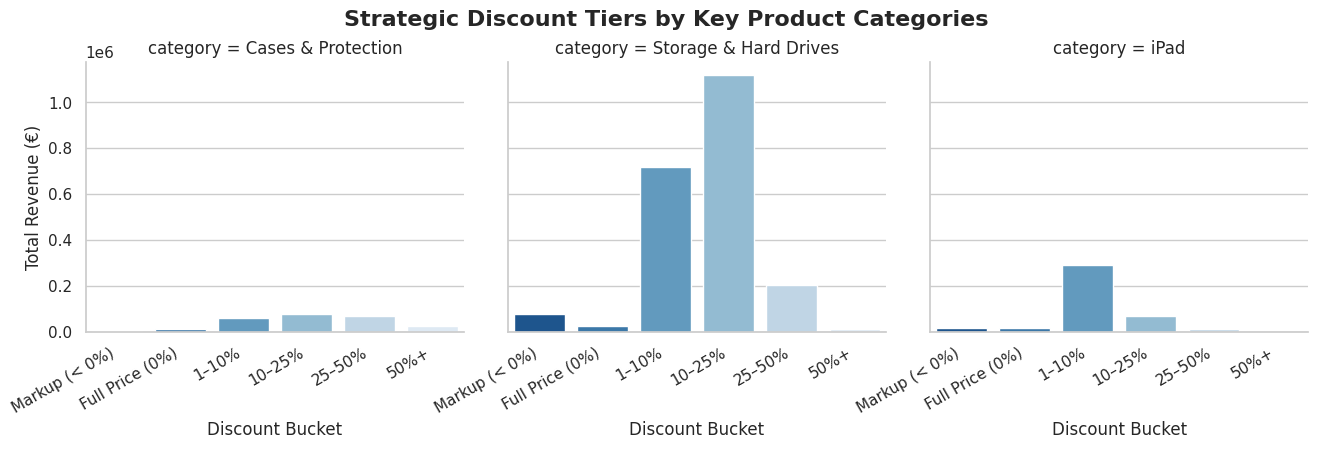

In [96]:
#Plot in Backup SLide
#FINAL PLOT - PRODUCT CATEGORIES & DISCOUNT BUCKETS

import matplotlib.pyplot as plt
import seaborn as sns

# 1. Select only 3 strategic categories to keep the slide clean
key_categories = ['iPad', 'Storage & Hard Drives', 'Cases & Protection']
filtered_data = merged_datasets[
    merged_datasets['category'].isin(key_categories)
]

# 2. Group data by discount bucket and category
category_revenue = (
    filtered_data.groupby(['discount_bucket', 'category'])['unit_price_total']
    .sum()
    .reset_index()
)

# 3. Define the logical order for discount buckets
bucket_order = [
    'Markup (< 0%)',
    'Full Price (0%)',
    '1–10%',
    '10–25%',
    '25–50%',
    '50%+',
]

# 4. Create a clean 3-column catplot
sns.set_theme(style='whitegrid')

g = sns.catplot(
    data=category_revenue,
    x='discount_bucket',
    y='unit_price_total',
    col='category',  # Creates exactly 3 side-by-side panels
    kind='bar',
    order=bucket_order,
    height=4,
    aspect=1.1,
    palette='Blues_r',
)

# 5. Format labels and titles with larger font sizes for presentation readability
g.set_axis_labels(
    'Discount Bucket', 'Total Revenue (€)', fontsize=12
)  # Increases axis label size
g.set_xticklabels(
    rotation=30, ha='right', fontsize=11
)  # Rotates cleanly and sizes X ticks

# Explicitly size Y-axis tick values across all subplots so they remain visible
for ax in g.axes.flat:
  ax.tick_params(axis='y', labelsize=11)

g.fig.subplots_adjust(top=0.85)
g.fig.suptitle(
    'Strategic Discount Tiers by Key Product Categories',
    fontsize=16,
    fontweight='bold',
)

# SVG EXPORT
plt.savefig(
    'strategic_discount_tiers_by_category.svg',
    format='svg',
    bbox_inches='tight',
    transparent=True,
)


plt.show()

#####Downloading the plot in .svg format

In [97]:
#Importing & downloading the .svg file

import os
print([f for f in os.listdir() if f.endswith('.svg')])

from google.colab import files
files.download('strategic_discount_tiers_by_category.svg')

['strategic_discount_tiers_by_category.svg', 'total_revenue_distribution_by_discount_bucket.svg', 'monthly_revenue_vs_median_discount.svg']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

/tmp/ipykernel_1286/2592133319.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(
/tmp/ipykernel_1286/2592133319.py:52: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([f'€{val*1e-6:.1f}M' for val in current_ticks], fontsize=10)


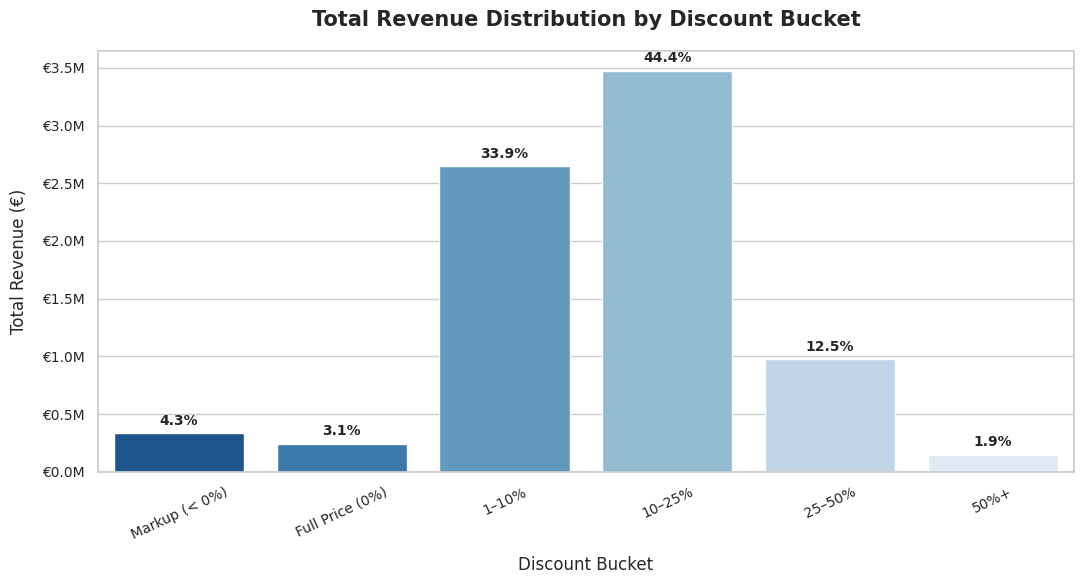

In [98]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Identify the revenue column name in your summary_revenue DataFrame
rev_col = (
    'unit_price_total'
    if 'unit_price_total' in summary_revenue.columns
    else 'total_revenue'
)

# 2. Calculate percentage share dynamically
total_sum = summary_revenue[rev_col].sum()
summary_revenue['revenue_share_pct'] = (
    summary_revenue[rev_col] / total_sum
) * 100

# 3. Define bucket order
bucket_order = [
    'Markup (< 0%)',
    'Full Price (0%)',
    '1–10%',
    '10–25%',
    '25–50%',
    '50%+',
]

# 4. Create bar plot using Seaborn
plt.figure(figsize=(11, 6))
sns.set_theme(style='whitegrid')

ax = sns.barplot(
    data=summary_revenue,
    x='discount_bucket',
    y=rev_col,
    order=bucket_order,
    palette='Blues_r',
)

# 5. Format labels and titles
plt.title(
    'Total Revenue Distribution by Discount Bucket',
    fontsize=15,
    fontweight='bold',
    pad=18,
)
plt.xlabel('Discount Bucket', fontsize=12, labelpad=10)
plt.ylabel('Total Revenue (€)', fontsize=12, labelpad=10)
plt.xticks(rotation=25, fontsize=10)

# 6. Format Y-axis in Millions (€M)
current_ticks = plt.yticks()[0]
ax.set_yticklabels([f'€{val*1e-6:.1f}M' for val in current_ticks], fontsize=10)

# 7. Map percentage labels to bar tops
pct_dict = dict(
    zip(
        summary_revenue['discount_bucket'],
        summary_revenue['revenue_share_pct'],
    )
)

for p, bucket in zip(ax.patches, bucket_order):
  height = p.get_height()
  if height > 0:
    pct_val = pct_dict.get(bucket, 0)
    ax.annotate(
        f'{pct_val:.1f}%',
        (p.get_x() + p.get_width() / 2.0, height),
        ha='center',
        va='bottom',
        xytext=(0, 4),
        textcoords='offset points',
        fontsize=10,
        fontweight='semibold',
    )

plt.tight_layout()
plt.show()

<Figure size 1200x800 with 0 Axes>

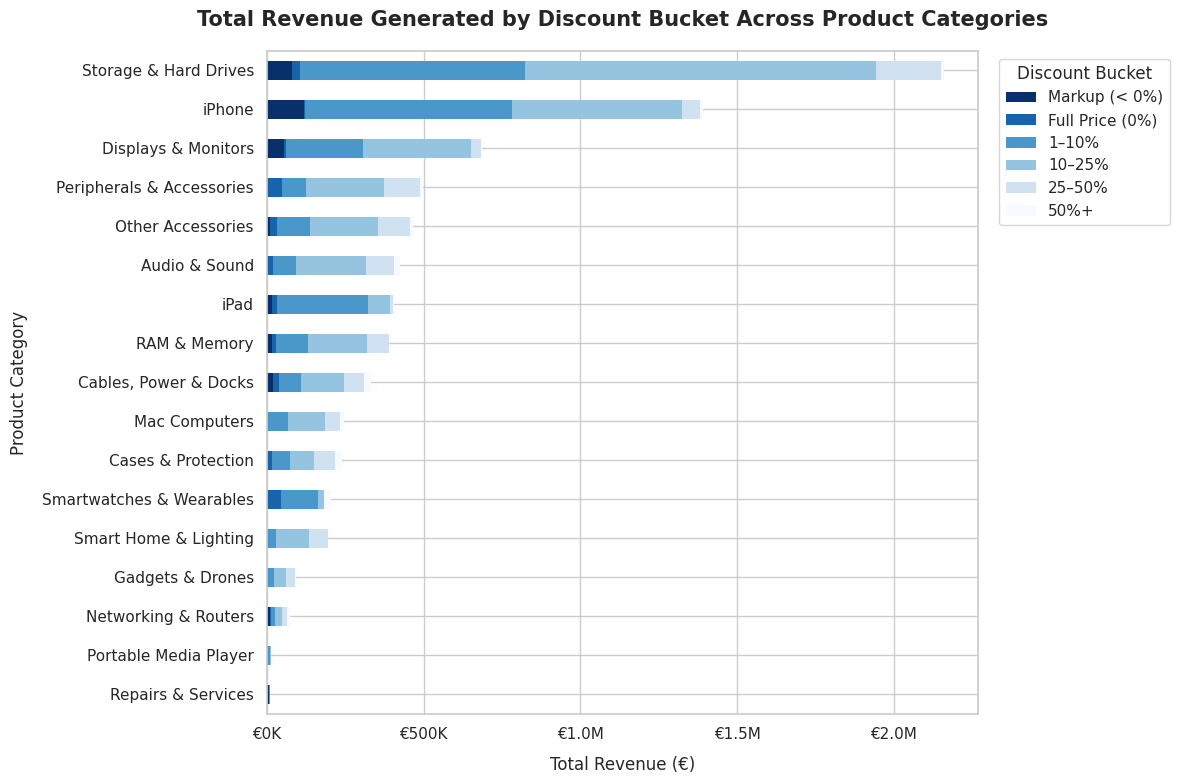

In [99]:
#Plot not in final presentation deck
#Plot for Total Revenue Generated by Discount Bucket Across Product Categories

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Define your canonical discount bucket order
bucket_order = [
    'Markup (< 0%)',
    'Full Price (0%)',
    '1–10%',
    '10–25%',
    '25–50%',
    '50%+',
]

# 2. Group data by category and discount bucket, summing total revenue
revenue_by_cat_bucket = (
    merged_datasets.groupby(['category', 'discount_bucket'])['unit_price_total']
    .sum()
    .unstack(fill_value=0)
)

# Reindex columns to ensure correct logical order and drop missing buckets if any
revenue_by_cat_bucket = revenue_by_cat_bucket.reindex(
    columns=bucket_order, fill_value=0
)

# 3. Sort categories by total revenue for a clean, hierarchical look
revenue_by_cat_bucket['Total'] = revenue_by_cat_bucket.sum(axis=1)
revenue_by_cat_bucket = revenue_by_cat_bucket.sort_values(
    by='Total', ascending=True
)
revenue_by_cat_bucket = revenue_by_cat_bucket.drop(columns=['Total'])

# 4. Set up the figure size and style
plt.figure(figsize=(12, 8))
sns.set_theme(style='whitegrid')

# 5. Create horizontal stacked bar chart using a polished blues palette
ax = revenue_by_cat_bucket.plot(
    kind='barh', stacked=True, figsize=(12, 8), colormap='Blues_r', edgecolor='none'
)

# 6. Formatting titles and labels
plt.title(
    'Total Revenue Generated by Discount Bucket Across Product Categories',
    fontsize=15,
    fontweight='bold',
    pad=18,
)
plt.xlabel('Total Revenue (€)', fontsize=12, labelpad=10)
plt.ylabel('Product Category', fontsize=12, labelpad=10)

# Format X-axis in Millions (€M)
from matplotlib.ticker import FuncFormatter

ax.xaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f'€{x*1e-6:.1f}M' if x >= 1e6 else f'€{x*1e-3:.0f}K')
)

# 7. Legend and layout
plt.legend(
    title='Discount Bucket',
    bbox_to_anchor=(1.02, 1),
    loc='upper left',
    frameon=True,
)
plt.tight_layout()
plt.show()

In [100]:
orders_s4.info()

<class 'pandas.core.frame.DataFrame'>
Index: 40985 entries, 1 to 226614
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   order_id      40985 non-null  int64         
 1   created_date  40985 non-null  datetime64[ns]
 2   total_paid    40985 non-null  float64       
 3   state         40985 non-null  object        
dtypes: datetime64[ns](1), float64(1), int64(1), object(1)
memory usage: 1.6+ MB


##Part 2: Set of code by 2nd group member
This being a group project the code from 2 notebooks is present in this merged notebook. This is the 2nd part.

In [101]:
# Add a year-month column (e.g. 2017-11) to group orders by month
orders_s4['year_month'] = orders_s4['created_date'].dt.to_period('M')

####Merging datasets for better analysis

In [102]:
orderlines_s4.merge(orders_s4, left_on='id_order', right_on='order_id')

,id,id_order,product_quantity,sku,unit_price,date,unit_price_total,order_id,created_date,total_paid,state,year_month
0,1119116,299545,1,OWC0100,47.49,2017-01-01 01:46:16,47.49,299545,2017-01-01 01:51:47,51.48,Completed,2017-01
1,1119119,299546,1,IOT0014,18.99,2017-01-01 01:50:34,18.99,299546,2017-01-01 01:57:34,18.99,Completed,2017-01
2,1119120,295347,1,APP0700,72.19,2017-01-01 01:54:11,72.19,295347,2017-01-01 02:02:38,72.19,Completed,2017-01
3,1119134,299556,1,CRU0039-A,60.90,2017-01-01 02:20:14,60.90,299556,2017-01-01 02:30:08,65.89,Completed,2017-01
4,1119145,299561,1,PEB0015,142.49,2017-01-01 02:38:50,142.49,299561,2017-01-01 02:39:47,154.48,Completed,2017-01
...,...,...,...,...,...,...,...,...,...,...,...,...
53226,1649447,527035,1,APP0698,9.99,2018-03-14 11:42:41,9.99,527035,2018-03-14 11:44:34,37.98,Completed,2018-03
53227,1649512,527070,2,APP0698,9.99,2018-03-14 11:49:01,19.98,527070,2018-03-14 11:50:48,24.97,Completed,2018-03
53228,1649522,527074,2,APP0698,9.99,2018-03-14 11:49:36,19.98,527074,2018-03-14 11:51:42,24.97,Completed,2018-03
53229,1649565,527096,3,APP0698,9.99,2018-03-14 11:54:35,29.97,527096,2018-03-14 11:58:40,34.96,Completed,2018-03


In [103]:
# Build one sales table: each row = one item sold, with its order date and product details

# 1. Add order date info to each order line (only the columns we need)
sales_df = orderlines_s4.merge(
    orders_s4[['order_id', 'created_date', 'year_month']],
    how='inner',
    left_on='id_order',     # order ID in orderlines
    right_on='order_id'     # same order ID in orders
)

# 2. Add the product name and regular price, matched by SKU
sales_df = sales_df.merge(
    products_s4[['sku', 'name', 'price']],
    how='inner',
    on='sku'
)

# Sanity check: row count should stay the same as orderlines
# (if it grows, a key was duplicated; if it shrinks, some rows had no match)
print("orderlines_s4:", orderlines_s4.shape[0])
print("sales_df     :", sales_df.shape[0])
sales_df.head()

orderlines_s4: 53231
sales_df     : 53231


,id,id_order,product_quantity,sku,unit_price,date,unit_price_total,order_id,created_date,year_month,name,price
0,1119116,299545,1,OWC0100,47.49,2017-01-01 01:46:16,47.49,299545,2017-01-01 01:51:47,2017-01,OWC In-line Digital Temperature Sensor Kit HDD iMac 2011,60.99
1,1119119,299546,1,IOT0014,18.99,2017-01-01 01:50:34,18.99,299546,2017-01-01 01:57:34,2017-01,iOttie Easy View 2 Car Black Support,22.95
2,1119120,295347,1,APP0700,72.19,2017-01-01 01:54:11,72.19,295347,2017-01-01 02:02:38,2017-01,"Apple 85W MagSafe 2 charger MacBook Pro screen Retina 15 ""(OEM)",89.00
3,1119134,299556,1,CRU0039-A,60.90,2017-01-01 02:20:14,60.90,299556,2017-01-01 02:30:08,2017-01,(Open) Crucial 240GB SSD 7mm BX200,76.99
4,1119145,299561,1,PEB0015,142.49,2017-01-01 02:38:50,142.49,299561,2017-01-01 02:39:47,2017-01,Pebble Smartwatch Time Steel Black,299.99


In [104]:
sales_df.head()

,id,id_order,product_quantity,sku,unit_price,date,unit_price_total,order_id,created_date,year_month,name,price
0,1119116,299545,1,OWC0100,47.49,2017-01-01 01:46:16,47.49,299545,2017-01-01 01:51:47,2017-01,OWC In-line Digital Temperature Sensor Kit HDD iMac 2011,60.99
1,1119119,299546,1,IOT0014,18.99,2017-01-01 01:50:34,18.99,299546,2017-01-01 01:57:34,2017-01,iOttie Easy View 2 Car Black Support,22.95
2,1119120,295347,1,APP0700,72.19,2017-01-01 01:54:11,72.19,295347,2017-01-01 02:02:38,2017-01,"Apple 85W MagSafe 2 charger MacBook Pro screen Retina 15 ""(OEM)",89.00
3,1119134,299556,1,CRU0039-A,60.90,2017-01-01 02:20:14,60.90,299556,2017-01-01 02:30:08,2017-01,(Open) Crucial 240GB SSD 7mm BX200,76.99
4,1119145,299561,1,PEB0015,142.49,2017-01-01 02:38:50,142.49,299561,2017-01-01 02:39:47,2017-01,Pebble Smartwatch Time Steel Black,299.99


In [105]:
# Create discount columns: how much below the regular price each item was sold
#discount_value = price - unit_price            (in €)
#discount_pct   = discount_value / price * 100  (in %)
# Positive = discounted, 0 = full price, negative = paid more than today's regular price

sales_df['discount_value'] = sales_df['price'] - sales_df['unit_price']   # € below the regular price
sales_df['discount_pct'] = sales_df['discount_value'] / sales_df['price'] * 100   # same, as a % of the regular price

In [106]:
(sales_df['discount_pct'] <= 0).sum()

np.int64(3827)

In [107]:
sales_df['discount_pct'].describe()

,discount_pct
count,53231.00
mean,21.38
std,18.15
min,-212.27
25%,9.09
50%,17.65
75%,28.59
max,97.14


In [108]:
#there is negative values involved from the above table, So what we are going to do is flag the value that are negative

sales_df['is_negative_discount'] = sales_df['discount_pct'] < 0

sales_df.sample(10)

,id,id_order,product_quantity,sku,unit_price,date,unit_price_total,order_id,created_date,year_month,name,price,discount_value,discount_pct,is_negative_discount
49534,1612664,511048,1,PHI0084,168.99,2018-02-13 23:28:01,168.99,511048,2018-02-13 23:29:17,2018-02,Philips Hue White and Color Ambiance Kit Incio E27 + DIM Switch White,199.99,31.00,15.50,False
39310,1508184,468198,1,ADN0043,72.99,2017-12-20 18:07:36,72.99,468198,2017-12-20 18:25:28,2017-12,Pixel Adonith pointer Bronze,74.99,2.00,2.67,False
26844,1390284,418503,1,LGE0036,168.99,2017-10-27 10:41:51,168.99,418503,2017-10-28 10:00:39,2017-10,"25UM58-P Monitor LG 25 ""widescreen IPS UHD Ultra",199.00,30.01,15.08,False
28722,1404923,425580,1,WAC0226,483.99,2017-11-11 23:29:10,483.99,425580,2017-11-11 23:33:59,2017-11,Paper Pro Intuos Graphics Tablet Black South L,599.90,115.91,19.32,False
41877,1528622,477951,1,PAC2477,33.98,2017-12-31 11:03:27,33.98,477951,2018-01-02 12:02:34,2018-01,Pack of 2 units Zagg Coda Wireless Headsets Black,59.98,26.00,43.35,False
16162,1289703,375935,1,WDT0325,294.99,2017-07-11 15:55:13,294.99,375935,2017-07-11 15:58:27,2017-07,Western Digital My Book Duo 6TB USB 3.0,329.99,35.00,10.61,False
42182,1530757,474732,1,ALL0015,28.40,2018-01-01 22:19:45,28.40,474732,2018-01-01 22:34:49,2018-01,Allocacoc PowerCube Extended Remote Power strip,34.95,6.55,18.74,False
11938,1249460,356595,1,LAC0201,119.99,2017-05-17 12:26:13,119.99,356595,2017-05-17 12:49:08,2017-05,Rugged Hard Disk 1TB USB-C USB 3.1,119.99,0.00,0.00,False
14926,1281846,372358,1,APP1747,455.00,2017-07-04 09:56:29,455.00,372358,2017-07-04 15:57:51,2017-07,Watch Apple Nike + 42mm Aluminum Case and Space Gray Nike Sport Strap Black / Volt,469.00,14.00,2.99,False
19713,1316682,388821,1,LAC0198,89.79,2017-08-11 19:28:37,89.79,388821,2017-08-11 19:41:09,2017-08,LaCie Porsche Design Mobile Hard Drive Disk USB 3.0 2TB,109.99,20.20,18.37,False


In [109]:
orderlines_s4.groupby('id_order').agg(total_price=('unit_price_total', 'sum'))

,total_price
id_order,
241423,129.16
242832,10.77
243330,77.99
245275,149.00
245595,105.98
...,...
527042,13.99
527070,19.98
527074,19.98


In [110]:
# Monthly summary: total revenue and typical discount per month
monthly = sales_df.groupby('year_month').agg(
    revenue=('unit_price_total', 'sum'),          # total money paid (price × quantity)
    median_discount=('discount_pct', 'median')    # median, so extreme discount values don't distort it
)
monthly

,revenue,median_discount
year_month,,
2017-01,604091.87,20.84
2017-02,332612.30,17.42
2017-03,24856.02,16.42
2017-04,228090.63,16.16
2017-05,331214.98,12.50
2017-06,286575.67,15.15
2017-07,599404.93,19.48
2017-08,379560.32,16.57
2017-09,387942.85,15.86


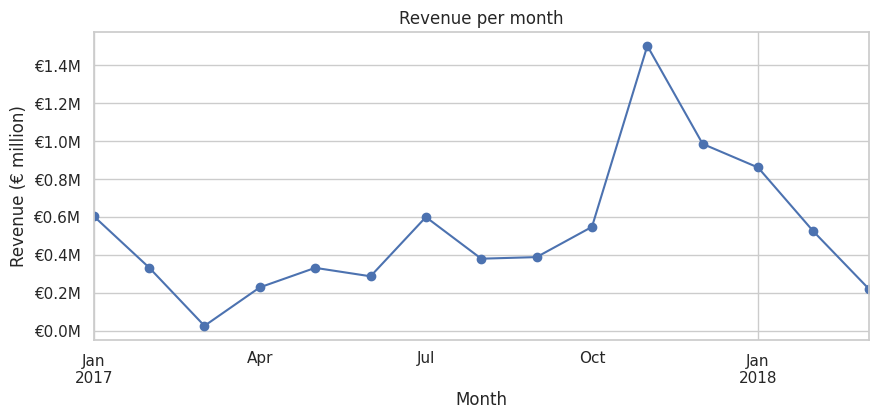

In [111]:
# Monthly totals: revenue and median discount per month
monthly = sales_df.groupby('year_month').agg(
    revenue=('unit_price_total', 'sum'),
    median_discount=('discount_pct', 'median')
)

# Line chart of monthly revenue (shown in € million for readability)
ax = (monthly['revenue'] / 1_000_000).plot(
    kind='line',
    marker='o',                  # dot on each month
    grid=True,
    figsize=(10, 4),
    title='Revenue per month',
    xlabel='Month',
    ylabel='Revenue (€ million)'
)

# Format y-axis labels as €0.5M, €1.0M, ...
ax.yaxis.set_major_formatter(lambda x, pos: f'€{x:.1f}M')

Data visualization( to make the label stand out)

In [112]:
import pandas as pd
import seaborn as sns

# Bigger, bolder text for ALL charts (presentation size)
sns.set_context('talk')                     # makes all text and lines bigger, made for slides

plt.rcParams['axes.titleweight'] = 'bold'   # chart titles in bold
plt.rcParams['figure.titleweight'] = 'bold' # big titles over several charts (suptitle) in bold
plt.rcParams['axes.labelsize'] = 15         # (b) axis labels, e.g. "Total revenue"
plt.rcParams['xtick.labelsize'] = 13        # (a) numbers / names on the x-axis
plt.rcParams['ytick.labelsize'] = 13        # (a) numbers on the y-axis
plt.rcParams['axes.titlesize'] = 17         # title size

#####Plot to display Seasonal Sale Trend

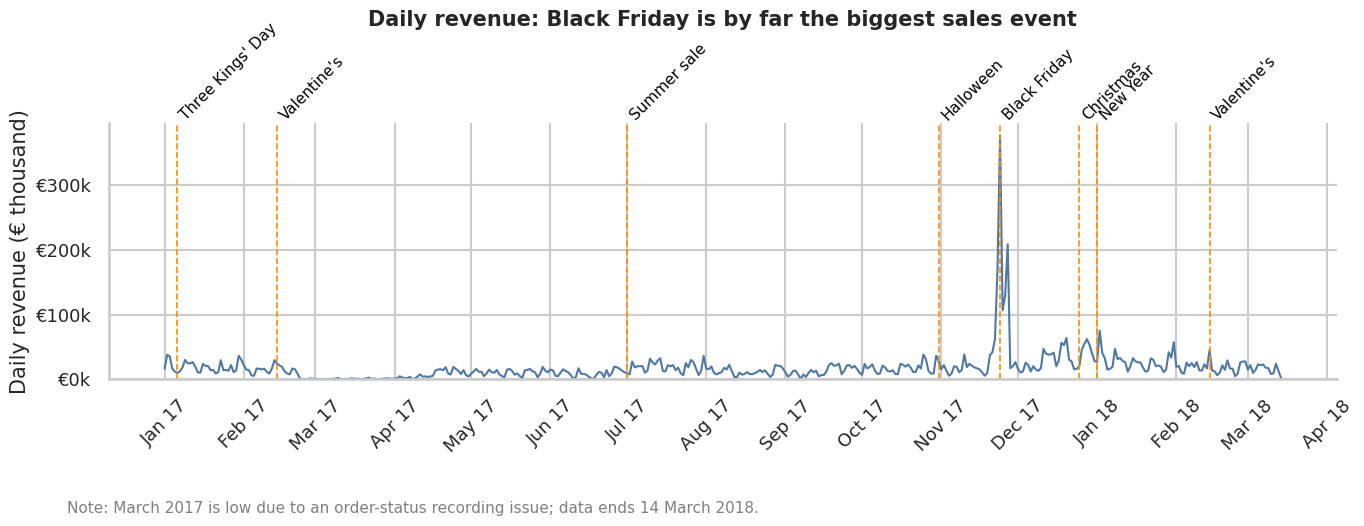

In [113]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# STEP 1: revenue per day
daily = sales_df.groupby(sales_df['created_date'].dt.date)['unit_price_total'].sum().reset_index()
daily.columns = ['date', 'revenue']
daily['date'] = pd.to_datetime(daily['date'])

# STEP 2: the special dates to mark
holidays = {
    '2017-01-06': "Three Kings' Day",
    '2017-02-14': "Valentine's",
    '2017-07-01': 'Summer sale',
    '2017-10-31': 'Halloween',
    '2017-11-24': 'Black Friday',
    '2017-12-25': 'Christmas',
    '2018-01-01': 'New Year',
    #'2018-01-06': "Three Kings' Day",
    '2018-02-14': "Valentine's",
}

# STEP 3: the chart
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(daily['date'], daily['revenue'] / 1000, color='#4E79A7', linewidth=1.5)

top = (daily['revenue'] / 1000).max() * 1.05      # a little above the highest day
ax.set_ylim(0, top)

for date, name in holidays.items():
    day = pd.Timestamp(date)
    ax.axvline(day, color='#FF8C00', linestyle='--', linewidth=1.2)
    ax.text(day, top, name, rotation=45, ha='left', va='bottom', fontsize=11, color='black')

# STEP 4: labels and polish
ax.set_ylabel('Daily revenue (€ thousand)')
ax.yaxis.set_major_formatter(lambda x, pos: f'€{x:.0f}k')
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %y'))
ax.tick_params(axis='x', rotation=45)

ax.set_title('Daily revenue: Black Friday is by far the biggest sales event', fontsize=15, pad=70)
fig.text(0.06, -0.06,
         'Note: March 2017 is low due to an order-status recording issue; data ends 14 March 2018.',
         fontsize=11, color='grey')

sns.despine()
plt.tight_layout()
plt.savefig('Seasonality_discount.svg', bbox_inches='tight', transparent=True)
plt.show()

#####Downloading the plot in .svg format

In [114]:
import os
print([f for f in os.listdir() if f.endswith('.svg')])

['strategic_discount_tiers_by_category.svg', 'total_revenue_distribution_by_discount_bucket.svg', 'Seasonality_discount.svg', 'monthly_revenue_vs_median_discount.svg']


In [115]:
from google.colab import files
files.download('Seasonality_discount.svg')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [116]:
sales_df.head()

,id,id_order,product_quantity,sku,unit_price,date,unit_price_total,order_id,created_date,year_month,name,price,discount_value,discount_pct,is_negative_discount
0,1119116,299545,1,OWC0100,47.49,2017-01-01 01:46:16,47.49,299545,2017-01-01 01:51:47,2017-01,OWC In-line Digital Temperature Sensor Kit HDD iMac 2011,60.99,13.50,22.13,False
1,1119119,299546,1,IOT0014,18.99,2017-01-01 01:50:34,18.99,299546,2017-01-01 01:57:34,2017-01,iOttie Easy View 2 Car Black Support,22.95,3.96,17.25,False
2,1119120,295347,1,APP0700,72.19,2017-01-01 01:54:11,72.19,295347,2017-01-01 02:02:38,2017-01,"Apple 85W MagSafe 2 charger MacBook Pro screen Retina 15 ""(OEM)",89.00,16.81,18.89,False
3,1119134,299556,1,CRU0039-A,60.90,2017-01-01 02:20:14,60.90,299556,2017-01-01 02:30:08,2017-01,(Open) Crucial 240GB SSD 7mm BX200,76.99,16.09,20.90,False
4,1119145,299561,1,PEB0015,142.49,2017-01-01 02:38:50,142.49,299561,2017-01-01 02:39:47,2017-01,Pebble Smartwatch Time Steel Black,299.99,157.50,52.50,False


####Finding out the sales in peak seasons

In [117]:
#  Creating a column to extract just the month details

sales_df['month'] = sales_df["created_date"].dt.month
sales_df[['created_date', 'month']].head()

,created_date,month
0,2017-01-01 01:51:47,1
1,2017-01-01 01:57:34,1
2,2017-01-01 02:02:38,1
3,2017-01-01 02:30:08,1
4,2017-01-01 02:39:47,1


In [118]:
#Analysing the sales in 2017 and 2018

sales_df['year'] = sales_df["created_date"].dt.year
sales_df[['created_date', 'year']].head()

,created_date,year
0,2017-01-01 01:51:47,2017
1,2017-01-01 01:57:34,2017
2,2017-01-01 02:02:38,2017
3,2017-01-01 02:30:08,2017
4,2017-01-01 02:39:47,2017


In [119]:
# Investigate the March 2017 revenue dip:
# is it a few missing days (data gap), or fewer orders spread across the whole month?

# Keep only March 2017 sales
march17 = sales_df.loc[(sales_df['year'] == 2017) & (sales_df['month'] == 3)]

# Count unique orders per day
daily = march17.groupby(march17['created_date'].dt.date)['id_order'].nunique()

print("Days with orders in March 2017:", len(daily), "out of 31")
daily
# Result: orders exist on all 31 days, but only ~5 per day (vs ~90 in a normal month),
# so it's not missing days; see next cell for the cause

Days with orders in March 2017: 31 out of 31


,id_order
created_date,
2017-03-01,11
2017-03-02,3
2017-03-03,2
2017-03-04,1
2017-03-05,4
2017-03-06,4
2017-03-07,5
2017-03-08,4
2017-03-09,6


In [120]:
# Was the March 2017 dip caused by our cleaning, or is it in the original data?
# Compare order counts per month at three stages: all orders, completed orders, and final cleaned data

# Work on a copy so orders_cl stays unchanged
check = orders_cl.copy()
check['created_date'] = pd.to_datetime(check['created_date'])
check['year_month'] = check['created_date'].dt.to_period('M')

monthly_check = pd.DataFrame({
    'all_orders':  check.groupby('year_month')['order_id'].count(),                                  # every order placed
    'completed':   check[check['state'] == 'Completed'].groupby('year_month')['order_id'].count(),   # only completed orders
    'in_sales_df': sales_df.groupby('year_month')['id_order'].nunique()                               # orders left after cleaning
})

monthly_check
# Result: March 2017 had a normal number of orders (10,726), but only 202 were "Completed" (~2% vs 16–27% in other months).
# The drop happens at the order-status step, not in our cleaning.

,all_orders,completed,in_sales_df
year_month,,,
2017-01,18844,5135,4597
2017-02,12182,2274,2045
2017-03,10726,202,163
2017-04,9943,1632,1460
2017-05,9631,1893,1651
2017-06,9920,1607,1329
2017-07,13829,3443,3074
2017-08,10347,2350,2098
2017-09,11533,2183,1880


In [121]:
# Result: in March 2017, "Pending" more than doubled (1,234 → 2,788) while "Completed" fell (2,274 → 202),
# so most March orders were never marked as completed: a status-recording issue, not a real drop in sales.
for ym in ['2017-06', '2017-07']:
    print(ym)
    print(check.loc[check['year_month'] == ym, 'state'].value_counts(), "\n")

2017-06
state
Shopping Basket    5018
Place Order        1879
Completed          1607
Pending            1065
Cancelled           351
Name: count, dtype: int64 

2017-07
state
Shopping Basket    6655
Completed          3443
Place Order        2653
Pending             598
Cancelled           480
Name: count, dtype: int64 



####Products vs. Revenue Analysis

In [122]:
# Top 5 products by revenue
# Group by SKU (unique product ID) and name (for readability), then sum the money each product brought in
top_revenue = (
    sales_df
    .groupby(['sku', 'name'])['unit_price_total']   # unit_price_total = price × quantity per order line
    .sum()
    .sort_values(ascending=False)                   # highest revenue first
    .head(5)
)
top_revenue

,,unit_price_total
sku,name,
LGE0044,"LG 27UD88-W Monitor 27 ""UHD 4K USB 3.0 USB-C",135375.83
APP2446,Apple iPhone 6 32GB Space Gray,104560.64
APP1922,AirPods Apple Bluetooth Headset for iPhone iPad iPod and Apple Watch,86473.26
APP2477,Apple iPhone 64GB Space Gray 8,85301.93
APP1970,Apple iPhone 32GB Space Gray,80715.76


In [123]:
# Total revenue across all completed orders (sum of price × quantity for every item sold)
total_revenue = sales_df['unit_price_total'].sum()
total_revenue   # ≈ €7.82M

np.float64(7817204.399999999)

####Seasonal Sale Analysis

In [124]:
# Flag sale-season months: Black Friday (Nov), Christmas (Dec), New Year (Jan), summer sale (Jul–Aug)
# True = order line from a sale month, False = normal month
sales_df['is_sale_season'] = sales_df['month'].isin([11, 12, 1, 7, 8])
sales_df['is_sale_season'].value_counts()

,count
is_sale_season,
True,33210
False,20021


In [125]:
# Revenue in sale-season months vs normal months
season_revenue = sales_df.groupby('is_sale_season')['unit_price_total'].sum()
season_revenue
# True  = sale-season months (Nov, Dec, Jan, Jul, Aug) → ≈ €4.93M
# False = normal months                               → ≈ €2.88M

,unit_price_total
is_sale_season,
False,2883400.92
True,4933803.48


In [126]:
season_revenue

,unit_price_total
is_sale_season,
False,2883400.92
True,4933803.48


In [127]:
season_revenue.sum()

np.float64(7817204.4)

In [128]:
season_plot = season_revenue.rename({True: 'Sale season', False: 'Normal months'})

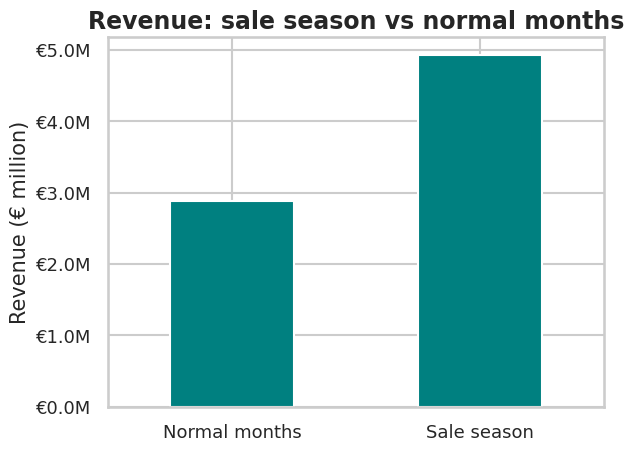

In [129]:
# Bar chart: total revenue in sale-season vs normal months (in € million)
ax = (season_plot / 1_000_000).plot(
    kind='bar',
    title='Revenue: sale season vs normal months',
    rot=0,                        # keep the bar labels horizontal
    ylabel='Revenue (€ million)',
    xlabel='',
    color='teal'
)

# Format y-axis labels as €1.0M, €2.0M, ...
ax.yaxis.set_major_formatter(lambda x, pos: f'€{x:.1f}M')

In [130]:
 #Percentage of revenue generated in sale (Revenue generated in sale duration VS. during normal days)

sale_pct = season_revenue[True] / season_revenue.sum() * 100
print(f"{sale_pct:.2f}% of revenue came from sale season")

63.11% of revenue came from sale season


In [131]:
#Sales sum in 2017
sales_df.groupby('year' )['unit_price_total'].sum()

,unit_price_total
year,
2017,6211445.91
2018,1605758.49


In [132]:
# Fair year-over-year comparison: 2018 only covers Jan to mid-March,
# so compare the months that are complete in both years (January + February)
jan_feb = sales_df.loc[sales_df['month'].isin([1, 2])]

# Revenue in Jan–Feb, per year
jan_feb.groupby('year')['unit_price_total'].sum()

,unit_price_total
year,
2017,936704.17
2018,1385092.53


In [133]:
#Find the median discount, revenue and orders completed in year 2017 and 2018 in Jan and Feb

jan_feb.groupby('year').agg(
    revenue = ('unit_price_total', 'sum'),
    orders = ('id_order', 'nunique'),
    median_discount = ('discount_pct', 'median')
)

,revenue,orders,median_discount
year,,,
2017,936704.17,6642,20.00
2018,1385092.53,7442,17.90


In [134]:
#Find the median discount, revenue and orders completed in year 2017 and 2018
sales_df.groupby('year').agg(revenue = ('unit_price_total', 'sum'),orders = ('id_order', 'nunique'),median_discount = ('discount_pct', 'median'))

,revenue,orders,median_discount
year,,,
2017,6211445.91,32189,17.49
2018,1605758.49,8796,18.05


In [135]:
#trying to isolate opened products

sales_df.loc[sales_df['sku'].str.contains(r'-A($|-)' ), ['sku','id_order', 'name']].sample(10)

/tmp/ipykernel_1286/3803474088.py:3: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  sales_df.loc[sales_df['sku'].str.contains(r'-A($|-)' ), ['sku','id_order', 'name']].sample(10)


,sku,id_order,name
53183,LAC0206-A,526843,Open - LaCie Porsche Design Desktop Lightgrey 4TB USB 3.0
21287,SEA0047-A,394586,"Open - 4TB Seagate Barracuda 35 ""SATA 5900rpm hard drive Mac and PC"
22137,AKI0015-A,399039,Open - Akitio NODE Case External Thunderbolt PCIe Graphics Card 3
49225,ADN0047-A,509733,Open - Adonit Jot Dash 3 Pointer Silver
5432,SAT0010-A,316753,Open - Satechi Sonic Dual Conical Mac v2.0 Speakers Black
10395,OWC0180-A,349954,"Open - OWC Accelsior S Adapter PCIe 2.5 ""Sata 6Gb / s SSD Mac Pro"
51676,DLL0048-A,519517,"Open - Dell UltraSharp U2718Q Monitor 27 ""4K"
40815,DLK0051-A,474010,Open - D-Link DCS-825L camera Babycam Wi-Fi baby monitor
14179,WDT0243-A,369324,"Open - Western Digital Network PC and Mac 6TB NAS 35 ""hard drive"
11573,SPE0127-A,355034,"Open - Speck SeeThru MacBook Pro Retina Clear housing 15 ""transparent"


####Pre owned products data analysis

In [136]:
# Flag pre-owned products (open box, like new, as new, second hand, graded)
# based on the condition prefix at the start of the product name, e.g. "Open - ..." or "(Open) ..."
# Regex: ^ = name starts with; (?: ... | ... ) = any one of these prefixes; \( \) = literal brackets
sales_df['is_open_box'] = sales_df['name'].str.contains(
    r'^(?:open - |like new - |as new - |second hand - |graded - |\(open\) )',
    case=False,     # ignore upper/lower case
    na=False,       # treat missing names as not pre-owned
    regex=True
)
sales_df['is_open_box'].value_counts()   # True = pre-owned, False = new

,count
is_open_box,
False,51442
True,1789


In [137]:
# Revenue per year: new vs pre-owned products
# .unstack() turns the result into a table: one row per year, one column each for new (False) and pre-owned (True)
open_box_rev = (
    sales_df
    .groupby(['year', 'is_open_box'])['unit_price_total']
    .sum()
    .unstack()
)
open_box_rev

is_open_box,False,True
year,,
2017,5846259.10,365186.81
2018,1486995.69,118762.80


In [138]:
open_top = (sales_df
    .loc[sales_df['is_open_box']]                  # 1. keep only open-box rows
    .groupby(['sku', 'name'])['unit_price_total']  # 2. one pile per product
    .sum()                                         #    revenue per product
    .sort_values(ascending=False)                  # 3. highest first
)
open_top.head(10)

,,unit_price_total
sku,name,
AP20264,Like new - Apple iPhone 7 Plus 128GB RED,41211.02
AP20311,Like new - Apple iPhone 6 32GB Space Gray,21197.77
AP20084,"Like new - Apple Macbook Air 13 ""i5 16GHz | 8GB RAM | 128GB Flash",13706.50
AP20260,Like new - Apple iPhone 7 128GB RED,11918.95
AP20174,Like new - Apple iPhone 7 32GB Black,10470.25
AP20321,Like new - Apple iPhone 7 32GB Gold,6731.55
LGE0038-A,"Open - LG 27UD88-W Monitor 27 ""UHD 4K USB 3.0 USB-C",6327.97
PAC1915,"Second hand - Apple iMac 215 ""Core i5 Quad-Core 27GHz | 8GB RAM | 1TB HDD",5438.50
AP20261,Like new - Apple iPhone 7 128GB Silver,5338.07


In [139]:
# New vs pre-owned products: typical discount, revenue, units sold and share of total revenue
open_summary = sales_df.groupby('is_open_box').agg(    # False = new, True = pre-owned
    median_discount=('discount_pct', 'median'),        # typical discount %
    revenue=('unit_price_total', 'sum'),               # total revenue
    items_sold=('product_quantity', 'sum')             # number of units sold
)

# Each group's share of total revenue, in %
open_summary['revenue_share_%'] = (
    open_summary['revenue'] / open_summary['revenue'].sum() * 100
).round(1)

open_summary
# Result: pre-owned items get a much higher median discount (~27.9% vs ~17.4%),
# but bring in only ~6.2% of revenue

,median_discount,revenue,items_sold,revenue_share_%
is_open_box,,,,
False,17.40,7333254.79,58158,93.80
True,27.94,483949.61,1853,6.20


#####Plot for pre-owned products displaying revenue generation & discount percentage

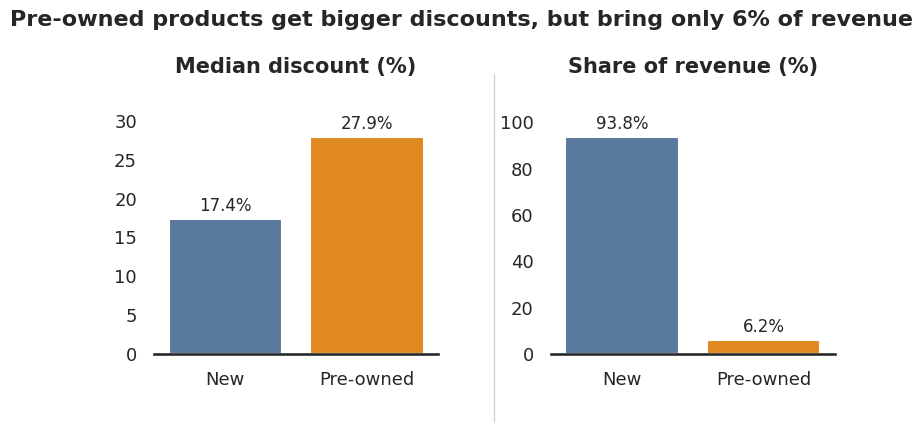

In [140]:
from matplotlib.lines import Line2D

# 1. Make a small table with readable names
plot_df = open_summary.reset_index()
plot_df['condition'] = plot_df['is_open_box'].map({False: 'New', True: 'Pre-owned'})

# 2. Put both measures in ONE column, so seaborn can draw them side by side
plot_long = plot_df.melt(
    id_vars='condition',
    value_vars=['median_discount', 'revenue_share_%'],
    var_name='measure',
    value_name='value'
)
plot_long['measure'] = plot_long['measure'].map({
    'median_discount': 'Median discount (%)',
    'revenue_share_%': 'Share of revenue (%)'
})

# 3. Draw: one small chart per measure
sns.set_style("white")

g = sns.catplot(
    kind='bar',
    data=plot_long,
    x='condition',
    y='value',
    col='measure',
    hue='condition',
    palette={'New': '#4E79A7', 'Pre-owned': '#FF8C00'},
    sharey=False,
    height=4,
    aspect=1,
    legend=False
)

# 4. Titles and labels
g.set_titles('{col_name}', pad=15)            # space under each chart title
g.set_axis_labels('', '')
g.figure.suptitle('Pre-owned products get bigger discounts, but bring only 6% of revenue',
                  fontsize=16, fontweight='bold', y=1.08)

# 5. Room above the bars + numbers on the bars
for ax in g.axes.flat:
    tallest = max(bar.get_height() for bar in ax.patches)
    ax.set_ylim(0, tallest * 1.2)             # 20% empty space above the tallest bar
    for bars in ax.containers:
        ax.bar_label(bars, fmt='%.1f%%', padding=3, fontsize=12)

sns.despine(left=True)

# 6. More space between the two charts + a thin grey divider line
g.figure.subplots_adjust(wspace=0.4)

left_chart = g.axes.flat[0].get_position()
right_chart = g.axes.flat[1].get_position()
middle = (left_chart.x1 + right_chart.x0) / 2

g.figure.add_artist(Line2D([middle, middle], [0.05, 0.92],
                           transform=g.figure.transFigure,
                           color='lightgrey', linewidth=1));
plt.savefig('preowned vs new products.svg', bbox_inches='tight', transparent=True)

#####Downloading the plot in .svg format

In [141]:
import os
print([f for f in os.listdir() if f.endswith('.svg')])

['strategic_discount_tiers_by_category.svg', 'total_revenue_distribution_by_discount_bucket.svg', 'Seasonality_discount.svg', 'monthly_revenue_vs_median_discount.svg', 'preowned vs new products.svg']


In [142]:
from google.colab import files
files.download('preowned vs new products.svg')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [143]:
# Add the final product category to every sale (drop any older category column first)
sales_df = sales_df.drop(columns=['category'], errors='ignore').merge(
    product_category_df[['sku', 'category']],
    on='sku',
    how='left'
)

In [144]:
# Sanity check after the merge
print("Rows:", sales_df.shape[0])                                  # should be unchanged (no rows added or lost)
print("Missing categories:", sales_df['category'].isna().sum())    # should be 0
print("Categories:", sales_df['category'].nunique())               # should be 17

Rows: 53231
Missing categories: 0
Categories: 17


In [145]:
# Review products that didn't match any keyword ("Other Accessories"), to spot missing rules
other_accessories = product_category_df.loc[
    product_category_df['category'] == 'Other Accessories', ['name', 'desc']
]
other_accessories.head(10)

,name,desc
0,Silver Rain Design mStand Support,Aluminum support compatible with all MacBook
22,Just Mobile Upstand iPad support,Support Retina iPad and iPad mini aluminum.
28,Sonnet Tempo SATA PCIe Mac and PC E2P,PCIe Card with 2 Serial ATA ports Mac and PC.
32,Music Receiver Belkin iPhone music receiver,Music Receiver iPhone iPad and iPod Touch for stereos via Bluetooth
33,KeyPad LMP Bluetooth Keypad Mac,expansion keypad Mac with bluetooth connection.
38,Just Mobile Lazy Couch Support Mac and iPad,Mac and iPad small lift stand.
40,Kensington ClickSafe lock Mac and PC,Mac and PC padlock with keys.
53,BlueLounge Milo iPhone and iPod black support,Desktop support iPhone and iPod.
54,Milo BlueLounge support iPhone and iPod white,Desktop support iPhone and iPod.
58,Moshi TeraGlove cleaner screens,Microfibre screen cleaner for Mac iPhone iPad and iPod.


# **Data visualization for analysis**

Investigating the relationship between the recommended price for a product (products.price) and the price that products actually sold for (orderlines.unit_price).

In [146]:
sales_df['is_discounted'] = sales_df['discount_pct'] > 0

In [147]:
sales_df.columns

Index(['id', 'id_order', 'product_quantity', 'sku', 'unit_price', 'date',
       'unit_price_total', 'order_id', 'created_date', 'year_month', 'name',
       'price', 'discount_value', 'discount_pct', 'is_negative_discount',
       'month', 'year', 'is_sale_season', 'is_open_box', 'category',
       'is_discounted'],
      dtype='object')

In [148]:
x =sales_df['is_discounted'].mean() * 100

print(f"Its safe to say that: {x:.3f}% of items sold below their shelf price, whihc is bad for the company's revenue")

Its safe to say that: 92.811% of items sold below their shelf price, whihc is bad for the company's revenue


####Scatter plot to display discounted products

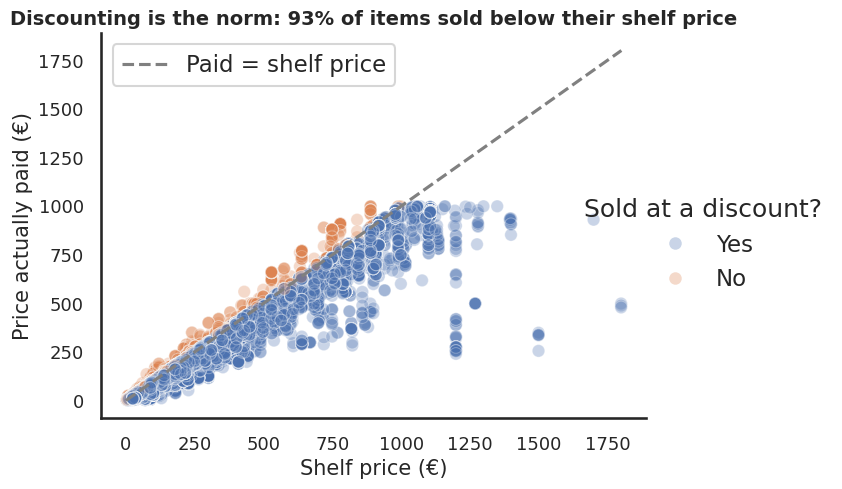

In [149]:
g = sns.relplot(
    kind="scatter",
    data=sales_df,
    x='price',
    y='unit_price',
    hue='is_discounted', # taking a true or false value
    hue_order=[True, False],  #It fixes the legend order, so the zip loop pairs True→“Yes” and False→“No” correctly
    alpha=0.3,  # determines the transparency , i.e:  0.3 will darken the dots when overlapping so we knwo that area has more sales
    height=5,  # to enlarge the graph or plot
    aspect=1.4  # as purpose to define clarity but for rows
)

# dashed reference line, with a name for the legend
line, = g.ax.plot([0, 1800], [0, 1800], linestyle='--', color='grey', label='Paid = shelf price')
g.ax.legend(handles=[line], loc='upper left')

#g.ax.plot([0, 1800], [0, 1800], linestyle='--', color='grey', label='Paid = shelf price') # The two lists are two points, (0, 0) and (1800, 1800). The line marks paid = shelf price. It doesn’t divide yes/no exactly (see below)
#g.ax.legend(loc='upper left')  # defines the legend

# title and axis labels
pct = sales_df['is_discounted'].mean() * 100
g.ax.set_title(f'Discounting is the norm: {pct:.0f}% of items sold below their shelf price', fontsize=14)
#g.ax.set_title('Most products sell below their shelf price', fontsize=14)
g.set_axis_labels('Shelf price (€)', 'Price actually paid (€)')

# make the colour legend readable
g.legend.set_title('Sold at a discount?')  #g.legend.texts: the list of words inside the legend. Here: ["True", "False"].
for text, new_label in zip(g.legend.texts, ['Yes', 'No']):  #['Yes', 'No']: your new words, in the same order., zip(...) pairs them up like a zipper
    text.set_text(new_label)

plt.savefig('Price_vs_discount.svg',transparent=True)

#####Downloading the plot in .svg format

In [150]:
print([f for f in os.listdir() if f.endswith('.svg')])
files.download('Price_vs_discount.svg')

['strategic_discount_tiers_by_category.svg', 'total_revenue_distribution_by_discount_bucket.svg', 'Seasonality_discount.svg', 'Price_vs_discount.svg', 'monthly_revenue_vs_median_discount.svg', 'preowned vs new products.svg']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Investigating when customers like to spend more money. Check how the average order price changes over time.

Hints:

choose a time scale on which you want to display the average order price. Should it be hourly, daily, weekly, yearly? Try different ones.
calculate the respective average of total_paid and make sure you have this saved as a DataFrame. Create your plot using this new DataFrame.

In [151]:
orders_s4.info()

<class 'pandas.core.frame.DataFrame'>
Index: 40985 entries, 1 to 226614
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   order_id      40985 non-null  int64         
 1   created_date  40985 non-null  datetime64[ns]
 2   total_paid    40985 non-null  float64       
 3   state         40985 non-null  object        
 4   year_month    40985 non-null  period[M]     
dtypes: datetime64[ns](1), float64(1), int64(1), object(1), period[M](1)
memory usage: 1.9+ MB


In [152]:
# Add month columns to the orders table
orders_s4['year_month'] = orders_s4['created_date'].dt.to_period('M').astype(str)  # e.g. "2017-11" (as text, for plotting)
orders_s4['month'] = orders_s4['created_date'].dt.month                             # month number 1–12

# Average order value per month (saved as a DataFrame for plotting)
avg_by_month = orders_s4.groupby('year_month').agg(
    avg_order=('total_paid', 'mean'),    # average amount paid per order
    orders=('order_id', 'count'),        # number of orders in that month
    month=('month', 'first')             # month number (same for all rows in the group, so take the first)
).reset_index()

# Label sale-season months: Black Friday (Nov), Christmas (Dec), New Year (Jan), summer sale (Jul–Aug)
avg_by_month['season'] = avg_by_month['month'].isin([11, 12, 1, 7, 8]).map(
    {True: 'Sale month', False: 'Normal month'}
)
avg_by_month

,year_month,avg_order,orders,month,season
0,2017-01,135.01,4597,1,Sale month
1,2017-02,167.16,2045,2,Normal month
2,2017-03,153.23,163,3,Normal month
3,2017-04,158.22,1460,4,Normal month
4,2017-05,202.26,1651,5,Normal month
5,2017-06,219.90,1329,6,Normal month
6,2017-07,198.61,3074,7,Sale month
7,2017-08,183.94,2098,8,Sale month
8,2017-09,210.62,1880,9,Normal month
9,2017-10,201.63,2768,10,Normal month


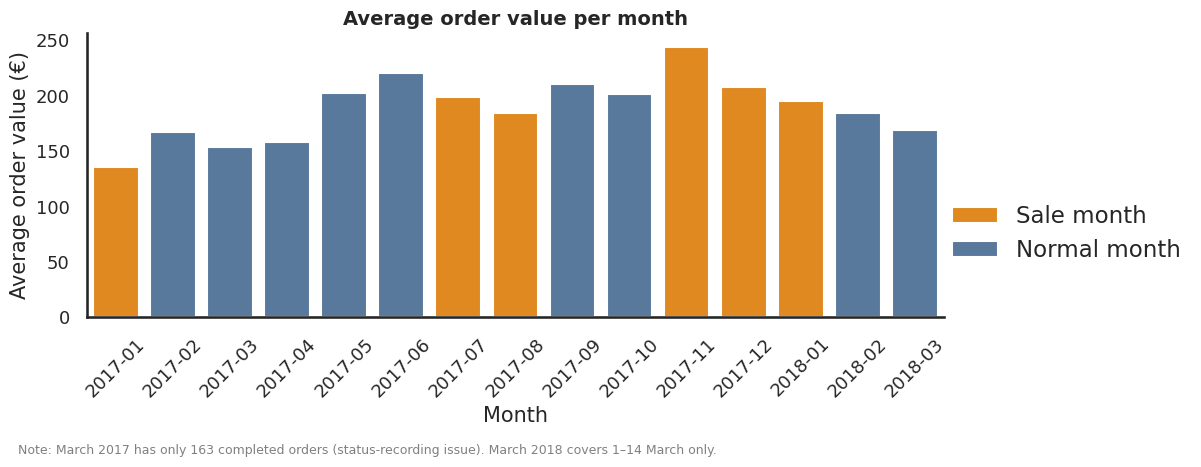

In [153]:
# Plot to display Average order value per month

g = sns.catplot(
    kind='bar',
    data=avg_by_month,
    x='year_month',
    y='avg_order',
    hue='season',
    palette={'Sale month': '#FF8C00', 'Normal month': '#4E79A7'},
    height=4,
    aspect=2.5
)

g.set_xticklabels(rotation=45)
g.set_axis_labels('Month', 'Average order value (€)')
g.ax.set_title('Average order value per month', fontsize=14)
g.legend.set_title('')
g.figure.text(0.05, -0.12,
    'Note: March 2017 has only 163 completed orders (status-recording issue). March 2018 covers 1–14 March only.',
    fontsize=9, color='grey')  #To add a footnote
sns.despine()

Trying to understand How does monthly revenue and the average discount rate impact on sales performance from 2017 to 2018 ?

In [154]:
#Lets take one row per month: revenue and median discount
monthly = sales_df.groupby('year_month').agg(revenue = ('unit_price_total', 'sum'), median_discount = ('discount_pct', 'median')).reset_index() # taking median as there are some outliers in pct

monthly['year_month'] = monthly['year_month'].astype(str)   # text labels for the x-axis
monthly['revenue'] = monthly['revenue'] / 1000               # show revenue in € thousand
monthly

,year_month,revenue,median_discount
0,2017-01,604.09,20.84
1,2017-02,332.61,17.42
2,2017-03,24.86,16.42
3,2017-04,228.09,16.16
4,2017-05,331.21,12.50
5,2017-06,286.58,15.15
6,2017-07,599.40,19.48
7,2017-08,379.56,16.57
8,2017-09,387.94,15.86
9,2017-10,547.60,17.41


In [155]:
# Readable labels for chart titles
monthly_long = monthly.melt(id_vars='year_month',value_vars=['revenue', 'median_discount'],var_name='measure',value_name='value')
monthly_long['measure'] = monthly_long['measure'].map({'revenue': 'Revenue (€ thousand)','median_discount': 'Median discount (%)'})

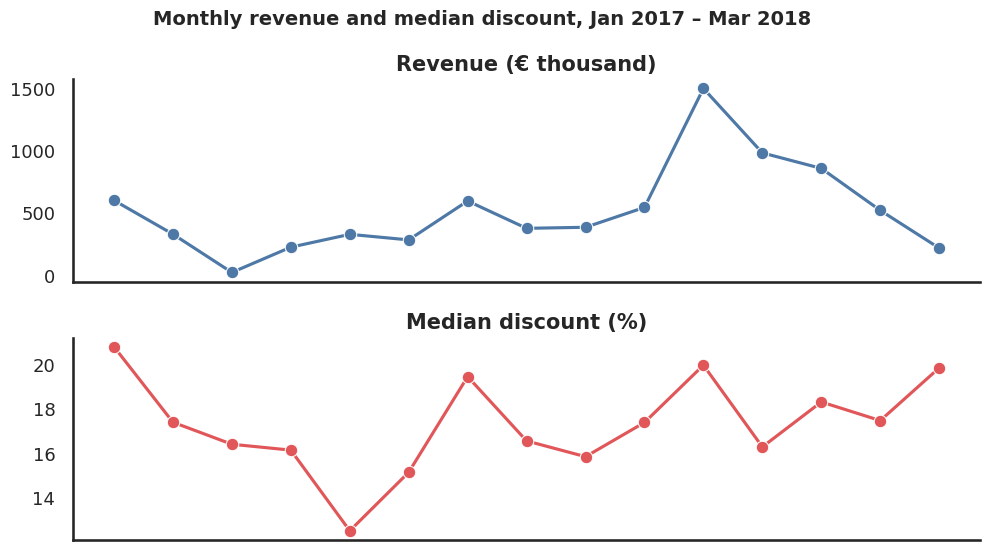

In [156]:
# two line charts, one above the other, same months
g = sns.relplot(
    kind='line',
    data=monthly_long,
    x='year_month',
    y='value',
    row='measure',
    hue='measure',
    palette={'Revenue (€ thousand)': '#4E79A7', 'Median discount (%)': '#E15759'},
    marker='o',
    height=3,
    aspect=3.5,
    facet_kws={'sharey': False},
    legend=False
)

g.set_titles('{row_name}')
g.set_axis_labels('', '')
g.set_xticklabels(rotation=45)
g.figure.suptitle('Monthly revenue and median discount, Jan 2017 – Mar 2018', fontsize=14, y=1.03)
sns.despine()

## **Discount impact**

In [157]:
import matplotlib.pyplot as plt

#one row per category: total revenue and median discount
cat_table = sales_df.groupby('category').agg(
    revenue = ('unit_price_total', 'sum'),
    median_discount = ('discount_pct', 'median')
).reset_index()

cat_table['revenue'] = cat_table['revenue'] / 1000                    # show revenue in € thousand
cat_table = cat_table.sort_values('revenue', ascending=False).reset_index(drop=True)
cat_table

,category,revenue,median_discount
0,Storage & Hard Drives,2159.43,15.86
1,iPhone,1389.66,13.43
2,Displays & Monitors,685.43,16.67
3,Peripherals & Accessories,496.85,19.61
4,Other Accessories,464.38,19.61
5,Audio & Sound,424.95,20.00
6,iPad,403.54,5.95
7,RAM & Memory,389.91,14.09
8,"Cables, Power & Docks",333.15,21.36
9,Mac Computers,245.15,13.65


In [158]:
cat_table['revenue'].sum()

np.float64(7817.2044000000005)

####Plot to display total revenue & median discount per product category

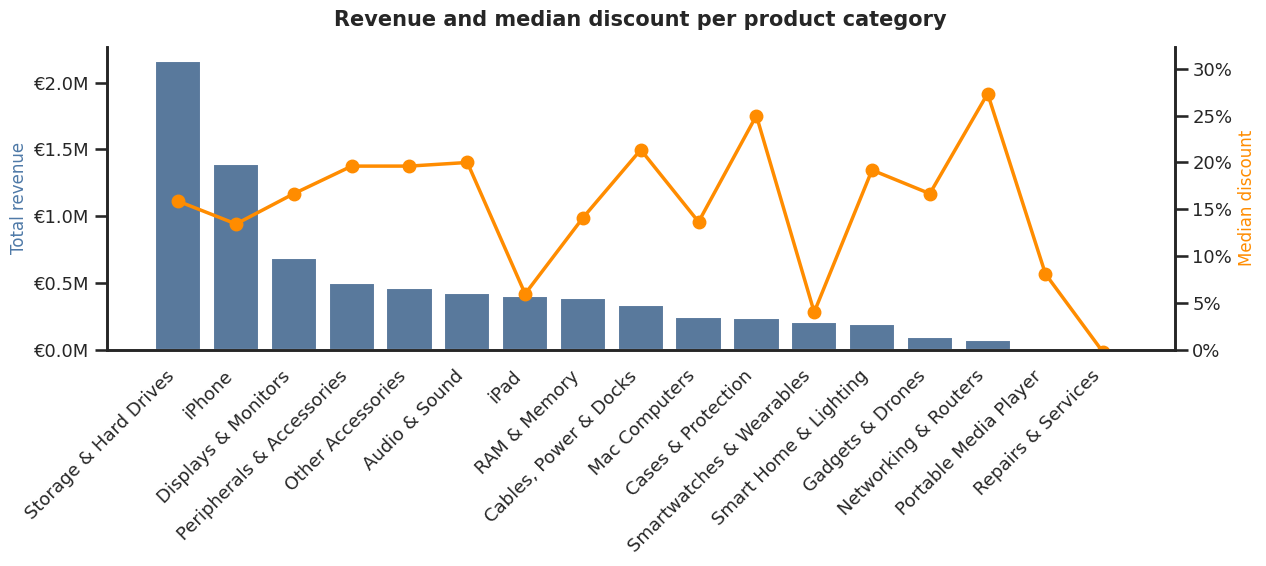

In [159]:
# the chart
fig, ax1 = plt.subplots(figsize=(13, 6))

# BARS: total revenue per category (left axis)
sns.barplot(data=cat_table, x='category', y='revenue', color='#4E79A7', ax=ax1)
ax1.set_ylabel('Total revenue', color='#4E79A7', fontsize=12)
#ax1.yaxis.set_major_formatter(lambda x, pos: f'€{x:.0f}k')   # axis numbers read €500k, €1000k …
ax1.yaxis.set_major_formatter(lambda x, pos: f'€{x/1000:.1f}M')
ax1.set_xlabel('')
ax1.tick_params(axis='x', rotation=45)
plt.setp(ax1.get_xticklabels(), ha='right')       # line the tilted names up with their bars

# LINE: median discount per category (right axis)
ax2 = ax1.twinx()
ax2.plot(range(len(cat_table)), cat_table['median_discount'],
         color='#FF8C00', marker='o', linewidth=2.5)
ax2.set_ylabel('Median discount', color='#FF8C00', fontsize=12)
ax2.yaxis.set_major_formatter(lambda x, pos: f'{x:.0f}%')    # axis numbers read 5%, 10% …
ax2.set_ylim(0, cat_table['median_discount'].max() + 5)

# title
ax1.set_title('Revenue and median discount per product category', fontsize=15, pad=15)
#ax1.bar_label(ax1.containers[0], fmt='€%.0fk', padding=3, fontsize=9)

sns.despine(right=False)    # keep the right border, because the discount axis lives there
plt.tight_layout()
plt.savefig('Revenue and median discount per product category.svg', bbox_inches='tight', transparent=True)
plt.show()

In [160]:
print([f for f in os.listdir() if f.endswith('.svg')])

['strategic_discount_tiers_by_category.svg', 'total_revenue_distribution_by_discount_bucket.svg', 'Seasonality_discount.svg', 'Price_vs_discount.svg', 'monthly_revenue_vs_median_discount.svg', 'preowned vs new products.svg', 'Revenue and median discount per product category.svg']


In [161]:
files.download('Revenue and median discount per product category.svg')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Plots displaying the top 10 products sold in January 2017 & the top 10 products sold in January 2018.
Highlighted products are the ones present in both years in the top 10 list.

In [162]:
#first we extract only January orders
jan = sales_df[sales_df['month'] == 1]

#top 10 products in January 2017 (by units sold)
jan17 = jan[jan['year'] == 2017]
top17 = jan17.groupby('name')['product_quantity'].sum().nlargest(10).reset_index()

#top 10 products in January 2018
jan18 = jan[jan['year'] == 2018]
top18 = jan18.groupby('name')['product_quantity'].sum().nlargest(10).reset_index()

#  is the product also in the OTHER year's top 10?
top17['in_both'] = top17['name'].isin(top18['name'])
top18['in_both'] = top18['name'].isin(top17['name'])

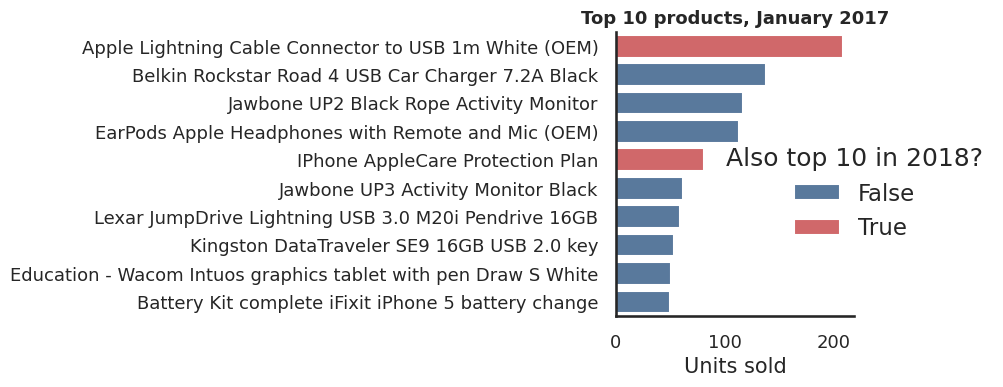

In [163]:
g = sns.catplot(
    kind='bar',
    data=top17,
    y='name',
    x='product_quantity',
    hue='in_both',
    palette={True: '#E15759', False: '#4E79A7'},
    height=4,
    aspect=2.5
)
g.set_axis_labels('Units sold', '')
g.ax.set_title('Top 10 products, January 2017', fontsize=13)
g.legend.set_title('Also top 10 in 2018?')
sns.despine()

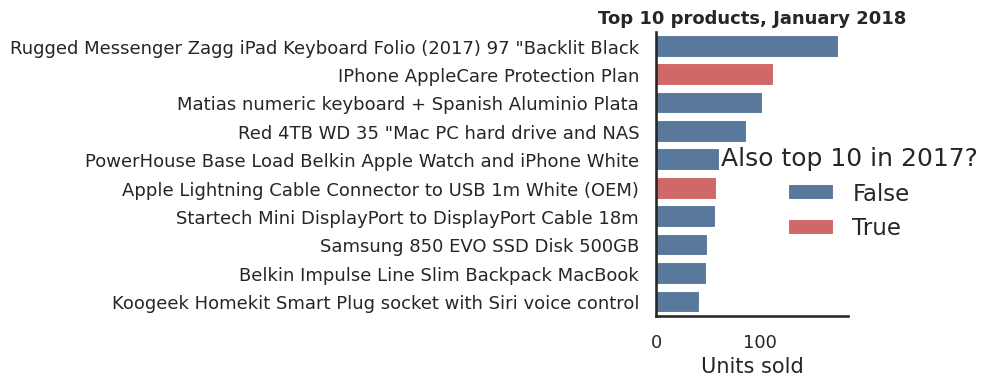

In [164]:
g = sns.catplot(
    kind='bar',
    data=top18,
    y='name',
    x='product_quantity',
    hue='in_both',
    palette={True: '#E15759', False: '#4E79A7'},
    height=4,
    aspect=2.5
)
g.set_axis_labels('Units sold', '')
g.ax.set_title('Top 10 products, January 2018', fontsize=13)
g.legend.set_title('Also top 10 in 2017?')
sns.despine()